# XÂY DỰNG PIPELINE TIỀN XỬ LÝ VÀ PHÂN LỚP DỮ LIỆU BẢNG (ADULT CENSUS INCOME)

## 1. Giới thiệu Bài toán và Bộ dữ liệu

Bài toán nghiên cứu nhằm giải quyết vấn đề phân loại nhị phân trên dữ liệu bảng: **Dự đoán liệu mức thu nhập hàng năm của một cá nhân có vượt quá 50.000 USD (`>50K`) hay không**, dựa trên các đặc trưng nhân khẩu học, trình độ học vấn, tình trạng hôn nhân và nghề nghiệp từ dữ liệu điều tra dân số Hoa Kỳ năm 1994 (**Adult Census Income Dataset**).

### Đặc điểm bài toán:
- **Biến mục tiêu (`income`):** Gồm 2 lớp:
  - Lớp đa số (`<=50K`): Thu nhập hàng năm không vượt quá 50.000 USD (~75% dữ liệu).
  - Lớp thiểu số (`>50K`): Thu nhập hàng năm vượt quá 50.000 USD (~25% dữ liệu).
- **Thách thức chính:** Dữ liệu có sự kết hợp giữa biến liên tục và biến phân loại nhiều nhóm, hiện tượng mất cân bằng lớp (Class Imbalance ~3:1), sự tồn tại của missing values ẩn (`'?'`), thông tin dư thừa (Redundancy) và biến giả mạo/nhiễu.

### Thiết kế Pipeline Khoa học:
1. **Kiểm soát rò rỉ dữ liệu (Strict Data Leakage Prevention):** Áp dụng mô hình 2 pha EDA (EDA Lần 1 trên dữ liệu thô toàn cục trước khi split; EDA Lần 2 chuyên sâu độc quyền trên tập Train sau khi split).
2. **Khả năng tái lập (Reproducibility):** Cố định hạt giống ngẫu nhiên `SEED = 42` xuyên suốt toàn bộ pipeline.
3. **So sánh đa thuật toán:** Triển khai và đánh giá khách quan 5 mô hình đại diện cho 5 trường phái học máy khác nhau: **XGBoost** (Ensemble Tree), **Multi-Layer Perceptron - MLP** (Deep Learning), **K-Nearest Neighbors - KNN** (Instance-based), **Gaussian Naive Bayes** (Bayesian Probability) và **Support Vector Machine - SVM** (Kernel Method).

## 1.2. Truy xuất Dữ liệu và Metadata Chuẩn từ UCI

Dữ liệu được nạp trực tiếp từ **UCI Machine Learning Repository** thông qua gói thư viện chính thức `ucimlrepo` (ID = 2). Việc truy xuất qua API bảo đảm tính toàn vẹn của lược đồ thuộc tính (Feature Schema), metadata gốc và thông tin định danh biến mà không qua trung gian chỉnh sửa thủ công.

In [ ]:
# Install the UCI dataset import package
%pip install -q ucimlrepo


In [ ]:
import random
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Cố định hạt giống ngẫu nhiên bảo đảm tính tái lập (Reproducibility)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Tải dữ liệu Adult trực tiếp từ kho lưu trữ UCI
adult = fetch_ucirepo(id=2)

# Tách riêng tập đặc trưng đầu vào và nhãn mục tiêu
X = adult.data.features
y = adult.data.targets

# Kết hợp thành một DataFrame hoàn chỉnh phục vụ khảo sát ban đầu
df = pd.concat([X, y], axis=1)

# Chuyển đổi các ký tự đại diện missing value ('?') trong dữ liệu gốc sang chuẩn np.nan
df = df.replace(r"^\s*\?\s*$", float("nan"), regex=True)

print("Tải dữ liệu thành công từ UCI Repository!")
print(f"Tổng số quan sát (Samples): {df.shape[0]:,}")
print(f"Tổng số thuộc tính (Features + Target): {df.shape[1]}")

Tải dữ liệu thành công từ UCI Repository!
Tổng số quan sát (Samples): 48,842
Tổng số thuộc tính (Features + Target): 15


In [ ]:
# Display dataset metadata
print("Dataset name:", adult.metadata.name)
print("UCI dataset ID:", adult.metadata.uci_id)
print("Number of instances:", adult.metadata.num_instances)
print("Number of features:", adult.metadata.num_features)
print("Target column:", adult.metadata.target_col)
print("Has missing values:", adult.metadata.has_missing_values)

# Display variable-level metadata
display(adult.variables)


Dataset name: Adult
UCI dataset ID: 2
Number of instances: 48842
Number of features: 14
Target column: ['income']
Has missing values: yes


,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,N/A,None,no
1,workclass,Feature,Categorical,Income,"Private, Self-emp-not-inc, Self-emp-inc, Feder...",None,yes
2,fnlwgt,Feature,Integer,None,None,None,no
3,education,Feature,Categorical,Education Level,"Bachelors, Some-college, 11th, HS-grad, Prof-...",None,no
4,education-num,Feature,Integer,Education Level,None,None,no
5,marital-status,Feature,Categorical,Other,"Married-civ-spouse, Divorced, Never-married, S...",None,no
6,occupation,Feature,Categorical,Other,"Tech-support, Craft-repair, Other-service, Sal...",None,yes
7,relationship,Feature,Categorical,Other,"Wife, Own-child, Husband, Not-in-family, Other...",None,no
8,race,Feature,Categorical,Race,"White, Asian-Pac-Islander, Amer-Indian-Eskimo,...",None,no
9,sex,Feature,Binary,Sex,"Female, Male.",None,no


In [ ]:
df.head()


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# 2. EDA Lần 1: Khảo sát Chất lượng Toàn cục & Làm sạch Dữ liệu trước Phân chia

## Cơ sở Lý luận của EDA Lần 1:
Trong quy trình khoa học dữ liệu chuẩn mực, **EDA Lần 1** được thực hiện trên **toàn bộ dữ liệu thô** nhằm đánh giá chất lượng thu thập trước khi chia tách thành các tập con. Các mục tiêu trọng tâm:
1. **Kiểm tra tính toàn vẹn cấu trúc:** Kích thước mẫu, kiểu dữ liệu, số lượng giá trị phân biệt.
2. **Định lượng và xử lý Missing Values:** Missing values trong bộ dữ liệu Adult được ký hiệu bằng ký tự `'?'` và chỉ tập trung ở ba thuộc tính phân loại: `workclass`, `occupation`, và `native-country`.
3. **Rà soát bản ghi trùng lặp và tính hợp lệ logic:** Phát hiện các dòng trùng lặp hoàn toàn và kiểm tra các ràng buộc thực tế (tuổi âm, số giờ làm việc âm, v.v.).

> **Lý giải về quyết định lọc bỏ missing values trước khi split:**
> Tổng số dòng chứa ít nhất một giá trị thiếu chiếm khoảng **7.4%** toàn bộ tập dữ liệu. Việc loại bỏ các quan sát thiếu này ngay ở cấp độ toàn cục trước khi split bảo đảm tập dữ liệu đưa vào phân tầng (Stratified Split) là hoàn chỉnh và sạch sẽ; qua đó tỉ lệ phân bố lớp mục tiêu giữa Train, Validation và Test được bảo toàn tuyệt đối chính xác mà không làm phát sinh dữ liệu khuyết thiếu ở các tập đánh giá độc lập.

## 2.1. Cấu trúc và Kích thước Dữ liệu

Khảo sát số lượng quan sát, số lượng đặc trưng, kiểu dữ liệu và số giá trị phân biệt của từng cột. Kết quả giúp xác định cấu trúc dữ liệu và lựa chọn các bước phân tích phù hợp.

In [ ]:
# Inspect dataset dimensions
n_samples, n_columns = df.shape
n_features = n_columns - 1  # Exclude target column

print(f"Number of samples: {n_samples:,}")
print(f"Number of input features: {n_features}")
print(f"Number of columns (including target): {n_columns}")

# Inspect column data types and unique counts
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Unique Values": df.nunique(dropna=True).values
    })
)


Number of samples: 48,842
Number of input features: 14
Number of columns (including target): 15


,Column,Data Type,Unique Values
0,age,int64,74
1,workclass,object,8
2,fnlwgt,int64,28523
3,education,object,16
4,education-num,int64,16
5,marital-status,object,7
6,occupation,object,14
7,relationship,object,6
8,race,object,5
9,sex,object,2


## 2.2. Phân tích Giá trị Thiếu (Missing Values)

Trong dữ liệu Adult Census Income, một số giá trị thiếu được biểu diễn bằng ký hiệu `?`. Các giá trị này đã được chuyển thành `NaN` khi nạp dữ liệu. Ta thống kê số lượng và tỷ lệ Missing Values theo từng đặc trưng, đồng thời xác định tỷ lệ quan sát có ít nhất một giá trị thiếu.

In [ ]:
import pandas as pd

# Count missing values in each column
missing_count = df.isnull().sum()

# Keep only columns that contain missing values
missing_summary = pd.DataFrame({
    "Missing Count": missing_count[missing_count > 0],
    "Missing Percentage (%)": (
        missing_count[missing_count > 0] / len(df) * 100
    ).round(2)
})

# Display the results
if missing_summary.empty:
    print("No missing values found in the dataset.")
else:
    missing_summary = missing_summary.sort_values(
        by="Missing Count", ascending=False
    )
    display(missing_summary)

    print(f"Total samples: {len(df):,}")
    print(f"Features with missing values: {len(missing_summary)}")


,Missing Count,Missing Percentage (%)
occupation,2809,5.75
workclass,2799,5.73
native-country,857,1.75


Total samples: 48,842
Features with missing values: 3


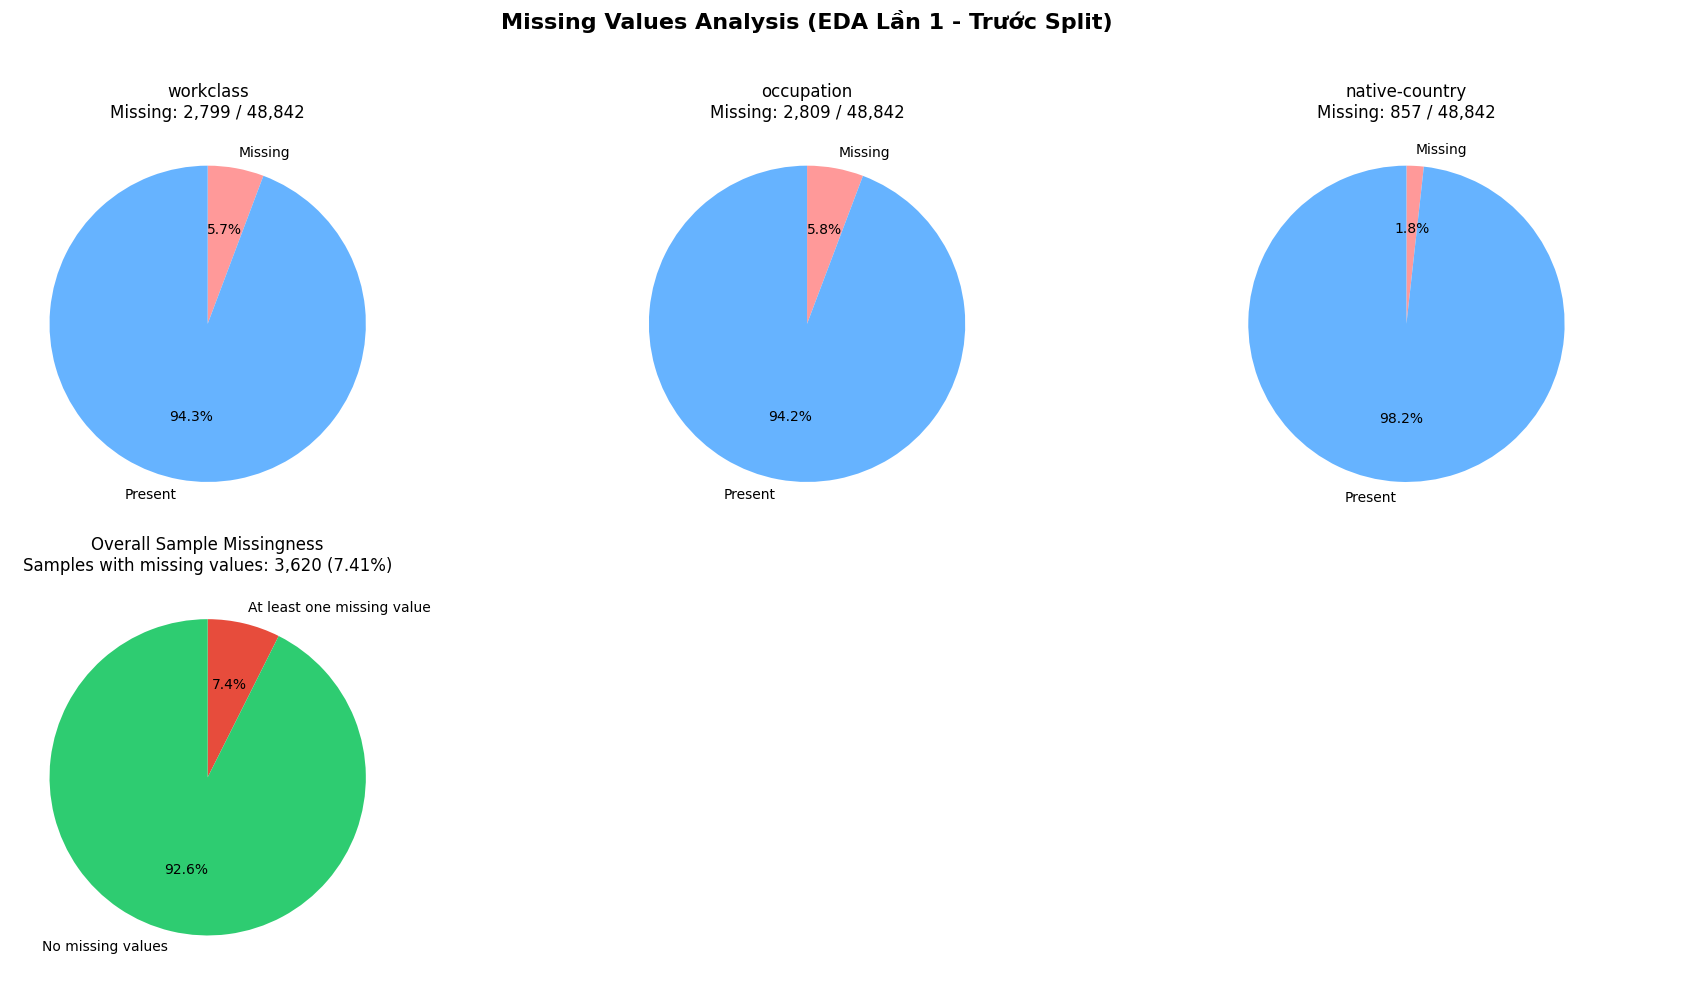

Chart saved to: /content/EDA_result/missing_values_analysis.png


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
import math

# Create output directory for EDA results
EDA_DIR = Path("EDA_result")
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Identify features containing missing values
missing_cols = df.columns[df.isnull().any()].tolist()

# Calculate samples with and without missing values
samples_with_missing = df.isnull().any(axis=1).sum()
samples_without_missing = len(df) - samples_with_missing

if not missing_cols:
    print("No missing values found. No pie charts were generated.")
else:
    n_plots = len(missing_cols) + 1  # Feature charts + overall chart
    n_cols = min(3, n_plots)
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 5 * n_rows)
    )
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    # Plot missing vs. non-missing values for each feature
    for i, col in enumerate(missing_cols):
        n_missing = df[col].isnull().sum()
        n_present = len(df) - n_missing

        axes[i].pie(
            [n_missing, n_present],
            labels=["Missing", "Present"],
            autopct="%1.1f%%",
            startangle=90,
            counterclock=False,
            colors=["#ff9999", "#66b3ff"]
        )
        axes[i].set_title(
            f"{col}\nMissing: {n_missing:,} / {len(df):,}"
        )

    # Plot the overall proportion of samples with missing values
    overall_idx = len(missing_cols)
    axes[overall_idx].pie(
        [samples_with_missing, samples_without_missing],
        labels=["At least one missing value", "No missing values"],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        colors=["#e74c3c", "#2ecc71"]
    )
    axes[overall_idx].set_title(
        "Overall Sample Missingness\n"
        f"Samples with missing values: {samples_with_missing:,} ({samples_with_missing / len(df) * 100:.2f}%)"
    )

    # Hide unused subplot axes
    for i in range(n_plots, len(axes)):
        axes[i].axis("off")

    fig.suptitle(
        "Missing Values Analysis (EDA Lần 1 - Trước Split)",
        fontsize=16,
        fontweight="bold"
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    output_path = EDA_DIR / "missing_values_analysis.png"
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Chart saved to: {output_path.resolve()}")


## 2.3. Kiểm tra Bản ghi Trùng lặp và Tính Hợp lệ

Bản ghi trùng lặp hoàn toàn có thể làm tăng mức độ đại diện của một số quan sát. Vì vậy, bước này thống kê số dòng trùng lặp và rà soát các giá trị vi phạm những ràng buộc logic cơ bản, chẳng hạn tuổi hoặc số giờ làm việc mang giá trị âm.

In [ ]:
# Count duplicated rows
duplicate_mask = df.duplicated()
n_duplicates = duplicate_mask.sum()
n_samples = len(df)

duplicate_percentage = (n_duplicates / n_samples * 100) if n_samples > 0 else 0

print(f"Total samples: {n_samples:,}")
print(f"Duplicate records: {n_duplicates:,}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")
print(f"Unique records: {n_samples - n_duplicates:,}")

# Check validity constraints on numerical features
invalid_checks = {
    "age": df["age"] < 0,
    "fnlwgt": df["fnlwgt"] < 0,
    "education-num": df["education-num"] < 0,
    "capital-gain": df["capital-gain"] < 0,
    "capital-loss": df["capital-loss"] < 0,
    "hours-per-week": df["hours-per-week"] < 0,
}

invalid_summary = []
for col, mask in invalid_checks.items():
    cnt = int(mask.sum())
    invalid_summary.append({
        "Feature": col,
        "Invalid Count": cnt,
        "Invalid Percentage (%)": round(cnt / len(df) * 100, 4)
    })

display(pd.DataFrame(invalid_summary))


Total samples: 48,842
Duplicate records: 29
Duplicate percentage: 0.06%
Unique records: 48,813


,Feature,Invalid Count,Invalid Percentage (%)
0,age,0,0.0
1,fnlwgt,0,0.0
2,education-num,0,0.0
3,capital-gain,0,0.0
4,capital-loss,0,0.0
5,hours-per-week,0,0.0


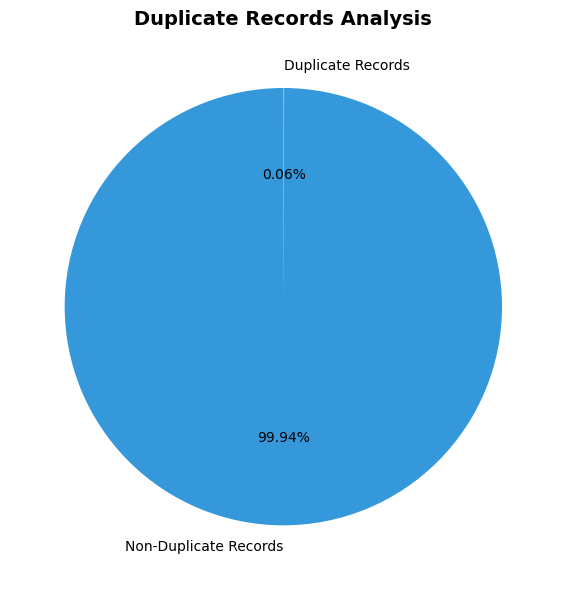

Chart saved to: /content/EDA_result/duplicate_records_analysis.png


In [ ]:
import matplotlib.pyplot as plt

# Visualize duplicate records
n_unique_records = n_samples - n_duplicates

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    [n_duplicates, n_unique_records],
    labels=["Duplicate Records", "Non-Duplicate Records"],
    autopct="%1.2f%%",
    startangle=90,
    counterclock=False,
    colors=["#f39c12", "#3498db"]
)
ax.set_title("Duplicate Records Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()

output_path = EDA_DIR / "duplicate_records_analysis.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Chart saved to: {output_path.resolve()}")


## 2.4. Làm sạch Missing Values

Các quan sát chứa ít nhất một giá trị thiếu (`NaN`) được loại bỏ trước khi chia tập. Nhãn `income` đồng thời được chuẩn hóa bằng cách loại bỏ khoảng trắng và dấu chấm ở cuối nhãn, nhằm thống nhất định dạng giữa các phần dữ liệu của nguồn UCI.

In [ ]:
# Normalize target labels before cleaning and splitting
df["income"] = df["income"].str.strip().str.rstrip(".")

# Store dataset size before cleaning
n_before = len(df)

# Filter missing values across the entire dataset
df_cleaned = df.dropna().copy()

n_after = len(df_cleaned)
n_dropped = n_before - n_after

print("=" * 60)
print("KẾT QUẢ LỌC BỎ NULL TRÊN TOÀN BỘ DATASET (EDA LẦN 1)")
print("=" * 60)
print(f"Số lượng mẫu ban đầu:              {n_before:,}")
print(f"Số lượng mẫu bị lọc bỏ (có null):   {n_dropped:,} ({n_dropped / n_before * 100:.2f}%)")
print(f"Số lượng mẫu sạch hoàn chỉnh:      {n_after:,} ({n_after / n_before * 100:.2f}%)")
print(f"Số giá trị missing còn lại:        {df_cleaned.isnull().sum().sum()}")
print("=" * 60)

# Verify clean dataset target distribution
print("\nPhân phối nhãn mục tiêu sau khi lọc null:")
display(df_cleaned["income"].value_counts(normalize=True).to_frame("Tỷ lệ (%)").assign(
    Số_mẫu=df_cleaned["income"].value_counts()
))


KẾT QUẢ LỌC BỎ NULL TRÊN TOÀN BỘ DATASET (EDA LẦN 1)
Số lượng mẫu ban đầu:              48,842
Số lượng mẫu bị lọc bỏ (có null):   3,620 (7.41%)
Số lượng mẫu sạch hoàn chỉnh:      45,222 (92.59%)
Số giá trị missing còn lại:        0

Phân phối nhãn mục tiêu sau khi lọc null:


,Tỷ lệ (%),Số_mẫu
income,,
<=50K,0.752156,34014
>50K,0.247844,11208


# 3. Phân chia Dữ liệu: Train, Validation và Test Split

Sau khi dữ liệu thô đã được làm sạch missing values, tập dữ liệu được phân chia thành ba tập con độc lập theo tỷ lệ chuẩn **70% Training / 15% Validation / 15% Testing**:
- **Training Set (70%):** Dành riêng cho việc thực hiện EDA Lần 2 (phân tích chuyên sâu), lựa chọn đặc trưng (Feature Selection), và học tham số tiền xử lý (`fit` encoder/scaler) cùng tham số mô hình.
- **Validation Set (15%):** Dùng để theo dõi quá trình huấn luyện, tinh chỉnh siêu tham số và so sánh hiệu năng giữa các mô hình.
- **Test Set (15%):** Bảo lưu hoàn toàn độc lập, chỉ được sử dụng ở bước cuối cùng để kiểm định khách quan khả năng tổng quát hóa (Generalization).

### Nguyên tắc Chống Rò rỉ Dữ liệu (Strict Data Leakage Prevention):
Tất cả các suy luận thống kê, ngưỡng phát hiện ngoại lai, ma trận tương quan, điểm thông tin tương hỗ (Mutual Information), và các bộ biến đổi (`OneHotEncoder`, `StandardScaler`) **bắt buộc phải được tính toán và học độc quyền trên tập Training**. Validation và Test chỉ đóng vai trò là dữ liệu chưa từng thấy (unseen data) và chỉ nhận phép biến đổi (`transform`) từ các tham số đã học.

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target from the cleaned dataset
X = df_cleaned.drop(columns=["income"])
y = df_cleaned["income"]

# Split into training (70%) and temporary (30%) sets with stratification
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split temporary set equally into validation (15%) and test (15%) sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display split summary
split_summary = pd.DataFrame({
    "Tập dữ liệu": ["Training (Train)", "Validation (Val)", "Testing (Test)", "Tổng cộng"],
    "Số lượng mẫu": [len(X_train), len(X_val), len(X_test), len(df_cleaned)],
    "Tỷ lệ (%)": [
        f"{len(X_train) / len(df_cleaned) * 100:.2f}%",
        f"{len(X_val) / len(df_cleaned) * 100:.2f}%",
        f"{len(X_test) / len(df_cleaned) * 100:.2f}%",
        "100.00%"
    ]
})

display(split_summary)


,Tập dữ liệu,Số lượng mẫu,Tỷ lệ (%)
0,Training (Train),31655,70.00%
1,Validation (Val),6783,15.00%
2,Testing (Test),6784,15.00%
3,Tổng cộng,45222,100.00%


In [ ]:
# Verify stratified target distributions across splits
target_dist = pd.DataFrame({
    "Train (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "Validation (%)": (y_val.value_counts(normalize=True) * 100).round(2),
    "Test (%)": (y_test.value_counts(normalize=True) * 100).round(2)
})

print("Phân phối nhãn mục tiêu trên từng tập (Kiểm tra tính phân tầng Stratification):")
display(target_dist)


Phân phối nhãn mục tiêu trên từng tập (Kiểm tra tính phân tầng Stratification):


,Train (%),Validation (%),Test (%)
income,,,
<=50K,75.21,75.22,75.22
>50K,24.79,24.78,24.78


# 4. EDA Lần 2: Phân tích Chuyên sâu và Ra Quyết định trên Training Set

**EDA Lần 2** được thực hiện **CHỈ TRÊN TẬP TRAINING (`X_train, y_train`)** nhằm mục đích khai phá bản chất dữ liệu để phục vụ trực tiếp cho các quyết định tiền xử lý và thiết kế mô hình:
1. **Phân tích mất cân bằng lớp (Class Imbalance):** Xác định hệ số mất cân bằng để thiết lập cơ chế bù trừ trọng số (`imbalance_ratio`) phù hợp cho từng thuật toán.
2. **Khảo sát phân phối đơn biến & Xử lý ngoại lai có điều kiện (Outlier Analysis):** Phân tích các trường hợp dị biệt cực đoan, áp dụng ngưỡng an toàn để quyết định loại bỏ mẫu nhiễu mà không làm méo mó phân phối dân số.
3. **Phân tích tương quan đa chiều qua Ma trận Pearson Toàn diện (Feature-Feature Multicollinearity):** Số hóa toàn bộ các thuộc tính để xây dựng ma trận tương quan cho tất cả đặc trưng, phát hiện hiện tượng đa cộng tuyến và thông tin dư thừa (Redundancy).
4. **Phân tích mối quan hệ giữa Đặc trưng và Biến mục tiêu (Feature-Target Relevance):** Kết hợp tương quan tuyến tính (Point-Biserial / Pearson) và thông tin tương hỗ (Mutual Information) để đánh giá sức mạnh dự đoán của từng đặc trưng.
5. **Lựa chọn đặc trưng có điều kiện (Optional Feature Selection):** Loại bỏ các đặc trưng dư thừa hoặc có mức độ liên quan quá thấp nếu thỏa mãn đầy đủ các điều kiện khoa học.

## 4.1. Phân tích Mất cân bằng Lớp (Class Imbalance)

Thống kê số lượng và tỷ lệ của hai lớp `<=50K` và `>50K` trên Training Set. Tỷ lệ giữa lớp đa số và lớp thiểu số được sử dụng để cân nhắc các phương pháp xử lý mất cân bằng trong quá trình huấn luyện.

Phân bố lớp được cập nhật lại sau bước kiểm tra Outlier nếu Training Set có thay đổi; tỷ lệ cập nhật mới là giá trị được sử dụng khi huấn luyện mô hình.

,Class,Sample Count,Percentage (%)
0,<=50K (Low Income),23809,75.21
1,>50K (High Income),7846,24.79


Số lượng mẫu âm tính (<=50K): 23,809
Số lượng mẫu dương tính (>50K): 7,846
Tỷ lệ mất cân bằng (Negative / Positive): 3.03 : 1


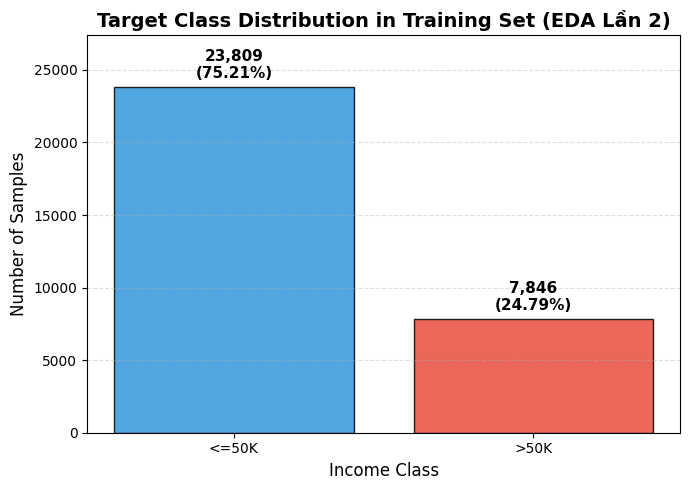

Biểu đồ đã được lưu tại: /content/EDA_result/target_class_distribution_train.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

EDA_DIR = Path("EDA_result")
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Calculate class distribution in the training set
train_counts = y_train.value_counts()
train_percentages = y_train.value_counts(normalize=True) * 100

class_imbalance_df = pd.DataFrame({
    "Class": ["<=50K (Low Income)", ">50K (High Income)"],
    "Sample Count": [train_counts.get("<=50K", 0), train_counts.get(">50K", 0)],
    "Percentage (%)": [train_percentages.get("<=50K", 0), train_percentages.get(">50K", 0)]
})

neg_count = train_counts.get("<=50K", 0)
pos_count = train_counts.get(">50K", 0)
imbalance_ratio = neg_count / pos_count

display(class_imbalance_df.round(2))
print(f"Số lượng mẫu âm tính (<=50K): {neg_count:,}")
print(f"Số lượng mẫu dương tính (>50K): {pos_count:,}")
print(f"Tỷ lệ mất cân bằng (Negative / Positive): {imbalance_ratio:.2f} : 1")

# Visualize target class distribution
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    ["<=50K", ">50K"],
    [neg_count, pos_count],
    color=["#3498db", "#e74c3c"],
    edgecolor="black",
    alpha=0.85
)

ax.set_title("Target Class Distribution in Training Set (EDA Lần 2)", fontsize=14, fontweight="bold")
ax.set_xlabel("Income Class", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar, pct in zip(bars, class_imbalance_df["Percentage (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 400,
        f"{int(bar.get_height()):,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_ylim(0, max(neg_count, pos_count) * 1.15)
fig.tight_layout()

output_path = EDA_DIR / "target_class_distribution_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


### Nhận xét và Hướng xử lý Class Imbalance

Tỷ lệ giữa hai lớp cho thấy mức độ mất cân bằng của Training Set. Khi lớp `>50K` ít hơn đáng kể, mô hình có thể thiên về dự đoán lớp đa số; do đó Accuracy đơn lẻ chưa phản ánh đầy đủ chất lượng phân loại.

Tỷ lệ `imbalance_ratio` được sử dụng làm cơ sở thiết lập `scale_pos_weight` cho XGBoost và `pos_weight` cho hàm mất mát của MLP. Các mô hình khác được đánh giá trên cùng Validation/Test Set; khác biệt về cơ chế xử lý mất cân bằng sẽ được xem xét khi diễn giải kết quả. Các chỉ số Precision, Recall, F1-score của lớp `>50K` và ROC-AUC được báo cáo bên cạnh Accuracy.

## 4.2. Phân tích Phân phối Đặc trưng (Univariate Analysis)

Thống kê mô tả, Histogram và Boxplot được sử dụng để quan sát hình dạng phân phối, độ lệch (`Skewness`) và phạm vi giá trị của các đặc trưng số. Với đặc trưng phân loại, ta khảo sát số nhóm giá trị và tần suất xuất hiện. Kết quả là cơ sở để nhận diện những điểm cần kiểm tra sâu hơn, không mặc định rằng mọi điểm nằm ngoài Boxplot đều là dữ liệu sai.

In [ ]:
# Identify numerical features in X_train
numerical_features = X_train.select_dtypes(include="number").columns.tolist()

# Descriptive statistics including median and skewness
num_stats = X_train[numerical_features].describe().T
num_stats["median"] = X_train[numerical_features].median()
num_stats["skewness"] = X_train[numerical_features].skew()
num_stats = num_stats[
    ["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max", "skewness"]
].round(2)

print("Thống kê mô tả các đặc trưng số trên tập Train:")
display(num_stats)


Thống kê mô tả các đặc trưng số trên tập Train:


,count,mean,median,std,min,25%,50%,75%,max,skewness
age,31655.0,38.58,37.0,13.21,17.0,28.0,37.0,47.0,90.0,0.53
fnlwgt,31655.0,190099.30,178322.0,105948.32,13769.0,117504.5,178322.0,238231.0,1490400.0,1.47
education-num,31655.0,10.12,10.0,2.56,1.0,9.0,10.0,13.0,16.0,-0.32
capital-gain,31655.0,1123.38,0.0,7613.14,0.0,0.0,0.0,0.0,99999.0,11.63
capital-loss,31655.0,89.79,0.0,407.20,0.0,0.0,0.0,0.0,4356.0,4.47
hours-per-week,31655.0,40.94,40.0,11.99,1.0,40.0,40.0,45.0,99.0,0.30


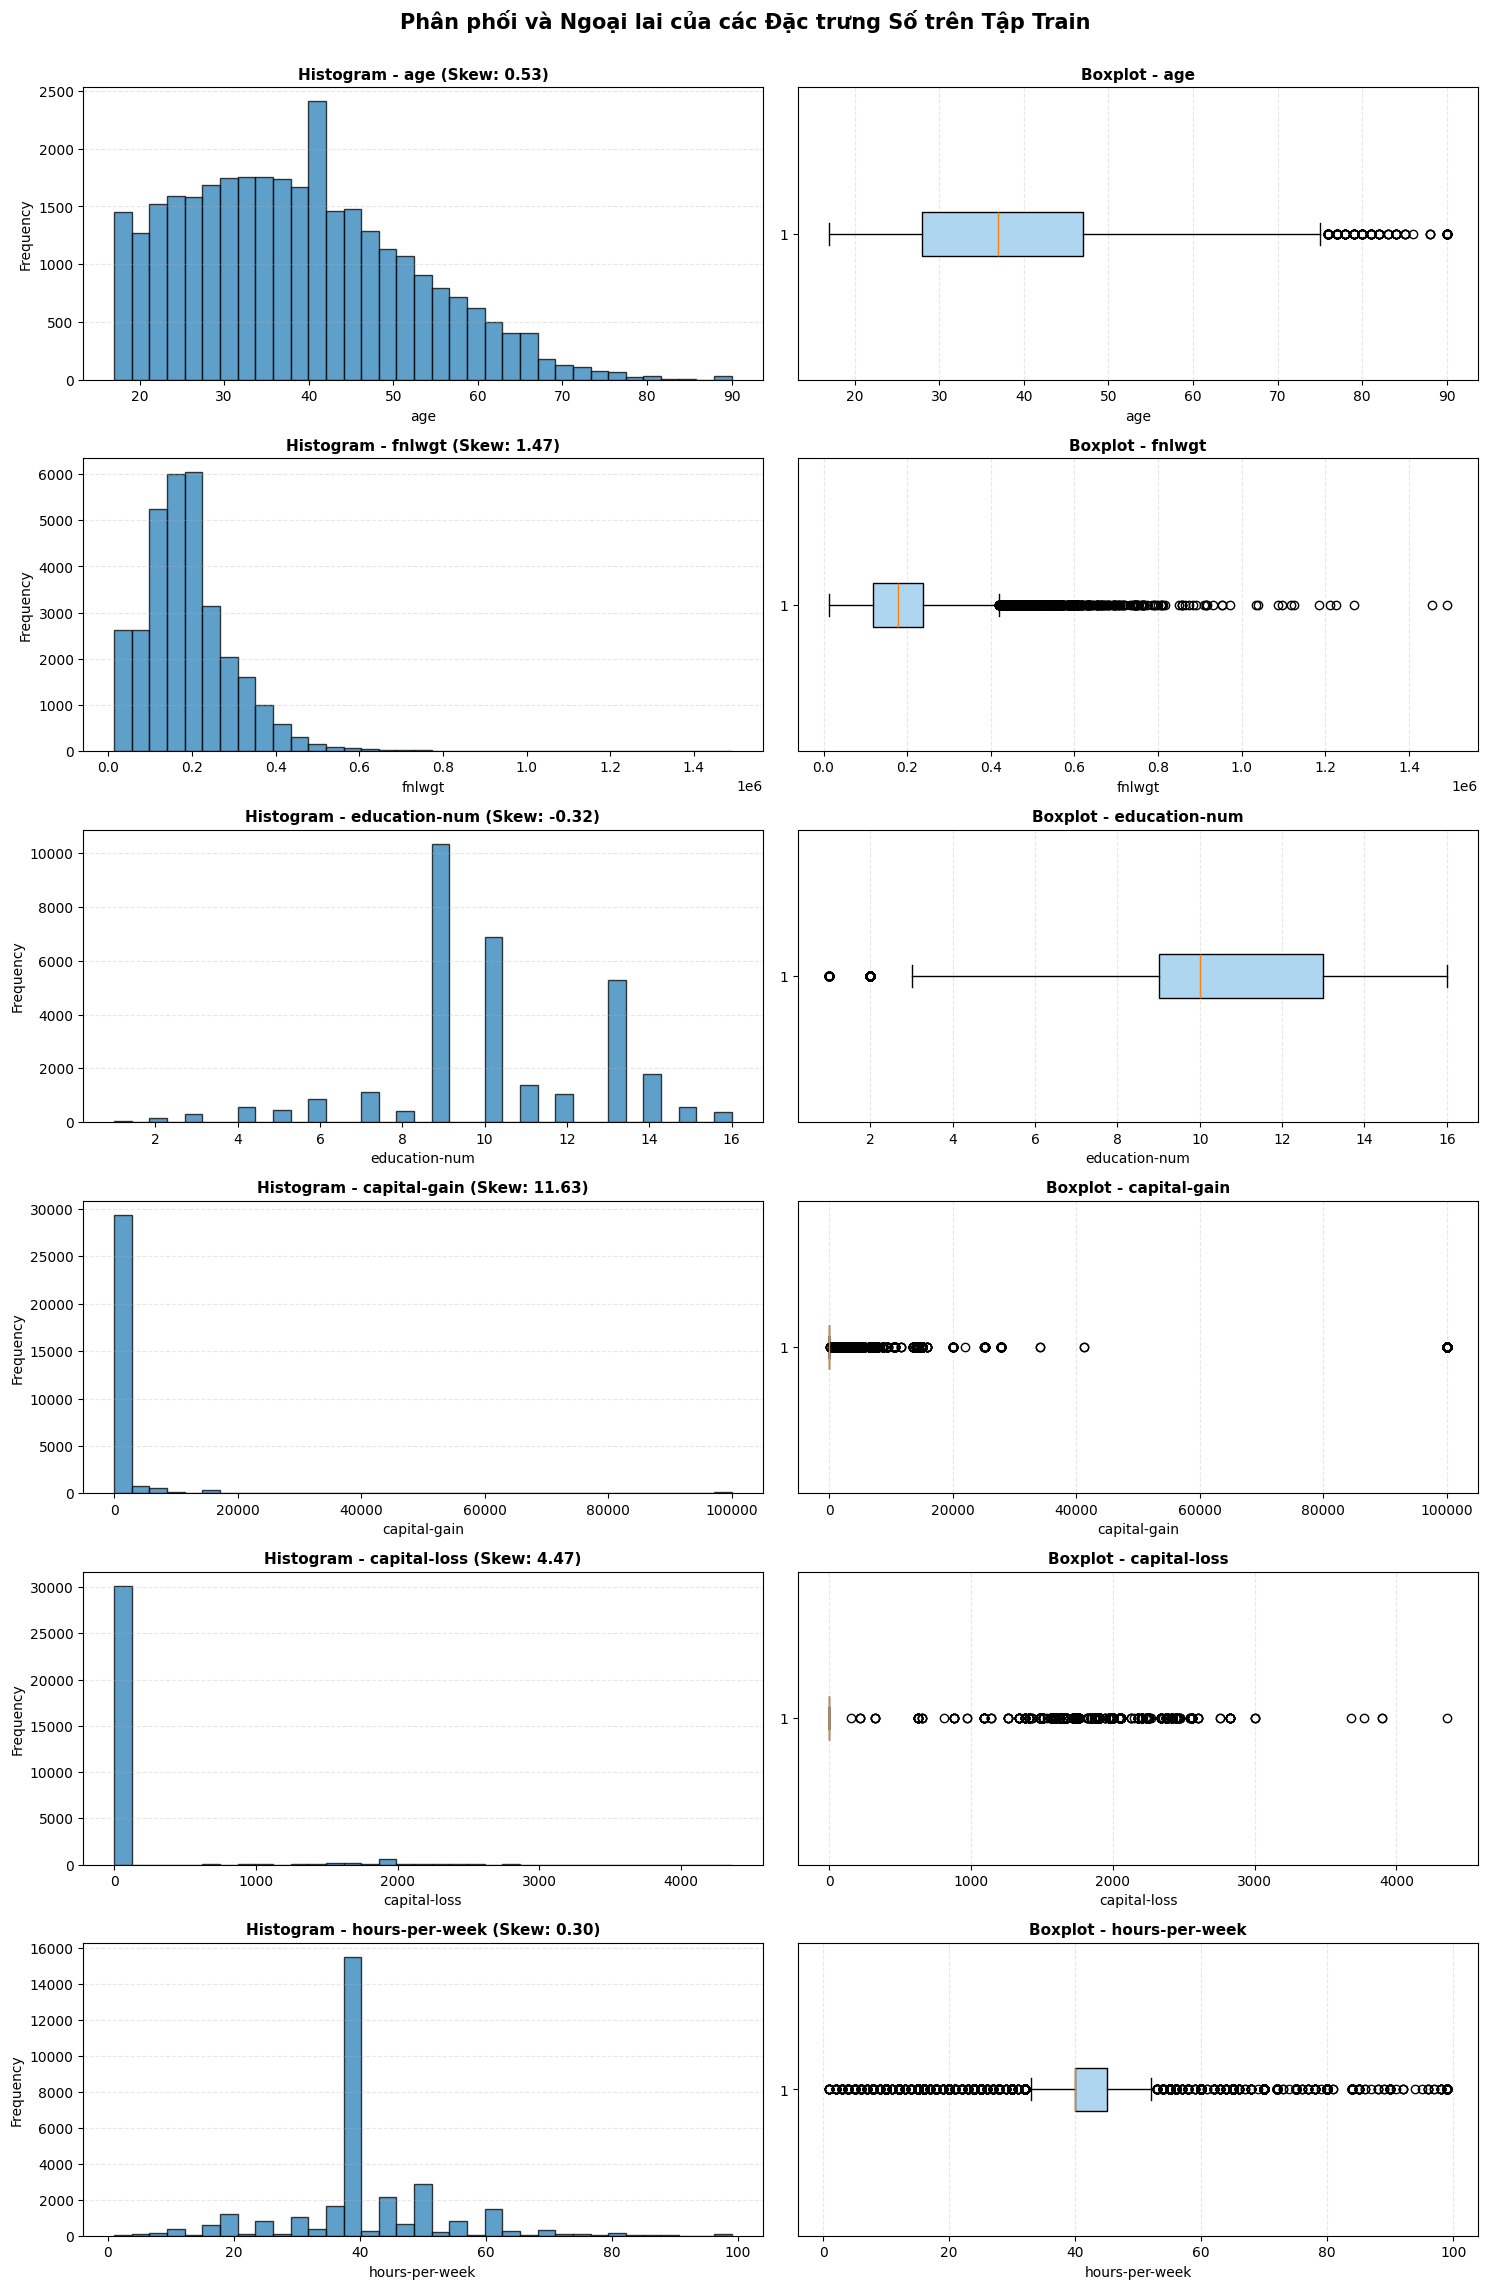

Biểu đồ đã được lưu tại: /content/EDA_result/numerical_feature_distributions_train.png


In [ ]:
import matplotlib.pyplot as plt

# Plot histograms and boxplots for numerical features in X_train
n_num = len(numerical_features)
fig, axes = plt.subplots(n_num, 2, figsize=(15, 3.8 * n_num))

for i, col in enumerate(numerical_features):
    vals = X_train[col].dropna()

    # Histogram
    axes[i, 0].hist(vals, bins=35, color="#2980b9", edgecolor="black", alpha=0.75)
    axes[i, 0].set_title(f"Histogram - {col} (Skew: {vals.skew():.2f})", fontsize=11, fontweight="bold")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frequency")
    axes[i, 0].grid(axis="y", linestyle="--", alpha=0.3)

    # Boxplot
    axes[i, 1].boxplot(vals, vert=False, patch_artist=True, boxprops=dict(facecolor="#aed6f1"))
    axes[i, 1].set_title(f"Boxplot - {col}", fontsize=11, fontweight="bold")
    axes[i, 1].set_xlabel(col)
    axes[i, 1].grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle("Phân phối và Ngoại lai của các Đặc trưng Số trên Tập Train", fontsize=15, fontweight="bold", y=1.002)
plt.tight_layout()

output_path = EDA_DIR / "numerical_feature_distributions_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


### 4.2.1. Kiểm định Ngoại lai (Outlier Analysis) và Cơ chế Loại bỏ An toàn có Điều kiện

Trong phân tích dữ liệu thực tế, việc xử lý ngoại lai đòi hỏi sự cẩn trọng và căn cứ khoa học rõ ràng, tránh loại bỏ cơ học dựa trên các biểu đồ đơn giản:

#### Cơ sở Lý luận về Ngoại lai trong Dữ liệu Nhân khẩu học:
1. **Các biến có phân phối Zero-Inflated (`capital-gain`, `capital-loss`):** Hơn 90% số cá nhân không có lợi tức hoặc tổn thất vốn đầu tư (mang giá trị 0). Nhóm thiểu số có giá trị dương lớn là những người có hoạt động đầu tư tài chính — đây chính là **chỉ báo kinh tế mạnh mẽ nhất** cho mức thu nhập cao `>50K`. Do đó, tuyệt đối không được loại bỏ các giá trị này để tránh làm mất tín hiệu then chốt của lớp thiểu số.
2. **Các biến liên tục (`age`, `hours-per-week`, `fnlwgt`, `education-num`):** Các giá trị phân hóa rộng (ví dụ làm việc bán thời gian 15-20 giờ/tuần hoặc làm thêm 60-70 giờ/tuần) phản ánh thực tế đa dạng của thị trường lao động. Chỉ các giá trị bất thường cực đoan (Severe Anomalies) vượt xa giới hạn thông thường mới được xem xét là nhiễu.

#### Thiết lập Ngưỡng Loại bỏ An toàn (Safe Pruning Threshold):
- Ta sử dụng quy tắc khoảng cách ngoại lai cực hạn của John Tukey: $[Q_1 - 3.0 	imes 	ext{IQR},\ Q_3 + 3.0 	imes 	ext{IQR}]$ trên các biến số thông thường.
- Trong Machine Learning, nguyên tắc làm sạch mẫu (Sample Pruning) an toàn là: **Tổng tỷ lệ mẫu ngoại lai bị loại bỏ chỉ được ở mức rất nhỏ, mang tính cục bộ ($\le 2.0\%$)**.
- **Cơ chế Loại bỏ Tùy chọn (Optional Removal):**
  - Nếu $0 < 	ext{Tỷ lệ ngoại lai} \le 2.0\%$: Thực hiện loại bỏ các mẫu nhiễu cực đoan này khỏi tập Training.
  - Nếu $	ext{Tỷ lệ ngoại lai} > 2.0\%$: **Không tự động loại bỏ (giữ nguyên tập Train)** nhằm bảo vệ tính toàn vẹn phân phối và tránh làm suy giảm dữ liệu của lớp thiểu số.
  - Nếu không có mẫu ngoại lai nào ($0\%$): Giữ nguyên.

In [ ]:
# Xác định ngoại lai cực đoan (Severe/Extreme Outliers) bằng quy tắc Tukey mở rộng (3.0 x IQR)
# Loại trừ các biến vốn có phân phối zero-inflated (capital-gain, capital-loss)
outlier_check_features = [
    col for col in numerical_features
    if col not in ["capital-gain", "capital-loss"]
]

outlier_flags = pd.DataFrame(False, index=X_train.index, columns=outlier_check_features)
outlier_summary = []

for col in outlier_check_features:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1

    if pd.isna(iqr) or iqr == 0:
        lower_bound, upper_bound = float("-inf"), float("inf")
    else:
        # Ngưỡng ngoại lai cực hạn (3.0 x IQR)
        lower_bound = q1 - 3.0 * iqr
        upper_bound = q3 + 3.0 * iqr

    col_flag = (X_train[col] < lower_bound) | (X_train[col] > upper_bound)
    outlier_flags[col] = col_flag
    outlier_summary.append({
        "Đặc trưng": col,
        "Ngưỡng dưới (3×IQR)": round(lower_bound, 2),
        "Ngưỡng trên (3×IQR)": round(upper_bound, 2),
        "Số mẫu cực đoan": int(col_flag.sum()),
        "Tỷ lệ (%)": round(100 * col_flag.mean(), 2)
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
print("Thống kê ngoại lai cực đoan theo từng đặc trưng trên tập Training:")
display(outlier_summary_df)

# Tổng hợp các quan sát bị gắn cờ cực đoan trên ít nhất một đặc trưng
outlier_row_mask = outlier_flags.any(axis=1)
n_outlier_rows = int(outlier_row_mask.sum())
outlier_percentage = 100 * n_outlier_rows / len(X_train) if len(X_train) else 0

# Thiết lập ngưỡng an toàn cho phép loại bỏ sample trong Machine Learning
OUTLIER_REMOVAL_THRESHOLD = 2.0  # Ngưỡng tối đa: 2.0% tập Train

print(f"\nTổng số mẫu bị gắn cờ ngoại lai cực đoan: {n_outlier_rows:,} ({outlier_percentage:.2f}%)")
print(f"Ngưỡng an toàn tối đa cho phép loại bỏ:    {OUTLIER_REMOVAL_THRESHOLD:.1f}%")

# Thực hiện loại bỏ có điều kiện (Optional Removal)
if 0 < outlier_percentage <= OUTLIER_REMOVAL_THRESHOLD:
    print(
        f"-> Quyết định: Tỷ lệ ({outlier_percentage:.2f}%) nằm trong ngưỡng an toàn (<= {OUTLIER_REMOVAL_THRESHOLD:.1f}%). "
        "Tiến hành loại bỏ các quan sát nhiễu cực đoan khỏi tập Training."
    )
    keep_mask = ~outlier_row_mask
    X_train = X_train.loc[keep_mask].copy()
    y_train = y_train.loc[keep_mask].copy()
elif n_outlier_rows == 0:
    print("-> Quyết định: Không phát hiện mẫu ngoại lai cực đoan; giữ nguyên tập Training.")
else:
    print(
        f"-> Quyết định: Tỷ lệ ({outlier_percentage:.2f}%) vượt ngưỡng an toàn {OUTLIER_REMOVAL_THRESHOLD:.1f}%. "
        "Các mẫu này phản ánh biến thiên tự nhiên của dân số. KHÔNG loại bỏ để bảo toàn dữ liệu và tránh méo mó phân phối."
    )

print(f"Kích thước tập Training hiện tại: {X_train.shape}")
assert X_train.index.equals(y_train.index), "X_train và y_train không còn đồng bộ index."


Thống kê ngoại lai cực đoan theo từng đặc trưng trên tập Training:


,Đặc trưng,Ngưỡng dưới (3×IQR),Ngưỡng trên (3×IQR),Số mẫu cực đoan,Tỷ lệ (%)
0,age,-29.0,104.0,0,0.00
1,fnlwgt,-244675.0,600410.5,149,0.47
2,education-num,-3.0,25.0,0,0.00
3,hours-per-week,25.0,60.0,3950,12.48



Tổng số mẫu bị gắn cờ ngoại lai cực đoan: 4,088 (12.91%)
Ngưỡng an toàn tối đa cho phép loại bỏ:    2.0%
-> Quyết định: Tỷ lệ (12.91%) vượt ngưỡng an toàn 2.0%. Các mẫu này phản ánh biến thiên tự nhiên của dân số. KHÔNG loại bỏ để bảo toàn dữ liệu và tránh méo mó phân phối.
Kích thước tập Training hiện tại: (31655, 14)


### Cập nhật phân bố lớp sau khi xử lý Outlier

Nếu bước kiểm tra ngoại lai có loại bỏ quan sát, tỷ lệ lớp trong Training Set có thể thay đổi. Vì vậy, ta tính lại `imbalance_ratio` trên dữ liệu Train cuối cùng trước khi sử dụng trong các mô hình.

In [ ]:
train_counts = y_train.value_counts()
neg_count = int(train_counts.get("<=50K", 0))
pos_count = int(train_counts.get(">50K", 0))
imbalance_ratio = neg_count / pos_count if pos_count else 1.0

class_imbalance_df = pd.DataFrame({
    "Class": ["<=50K", ">50K"],
    "Sample Count": [neg_count, pos_count],
    "Percentage (%)": [
        100 * neg_count / len(y_train),
        100 * pos_count / len(y_train)
    ]
})
display(class_imbalance_df.round(2))
print(f"Imbalance ratio (<=50K / >50K): {imbalance_ratio:.3f}")


,Class,Sample Count,Percentage (%)
0,<=50K,23809,75.21
1,>50K,7846,24.79


Imbalance ratio (<=50K / >50K): 3.035


In [ ]:
# Analyze categorical features in X_train
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

cat_summary = []
for col in categorical_features:
    n_unique = X_train[col].nunique()
    top_val = X_train[col].mode()[0]
    top_pct = (X_train[col] == top_val).mean() * 100
    cat_summary.append({
        "Feature": col,
        "Unique Categories": n_unique,
        "Top Category": top_val,
        "Top Category (%)": round(top_pct, 2)
    })

print("Tổng quan các đặc trưng phân loại trên tập Train:")
display(pd.DataFrame(cat_summary))


Tổng quan các đặc trưng phân loại trên tập Train:


,Feature,Unique Categories,Top Category,Top Category (%)
0,workclass,7,Private,73.54
1,education,16,HS-grad,32.70
2,marital-status,7,Married-civ-spouse,46.44
3,occupation,14,Prof-specialty,13.45
4,relationship,6,Husband,41.22
5,race,5,White,86.00
6,sex,2,Male,67.45
7,native-country,41,United-States,91.31


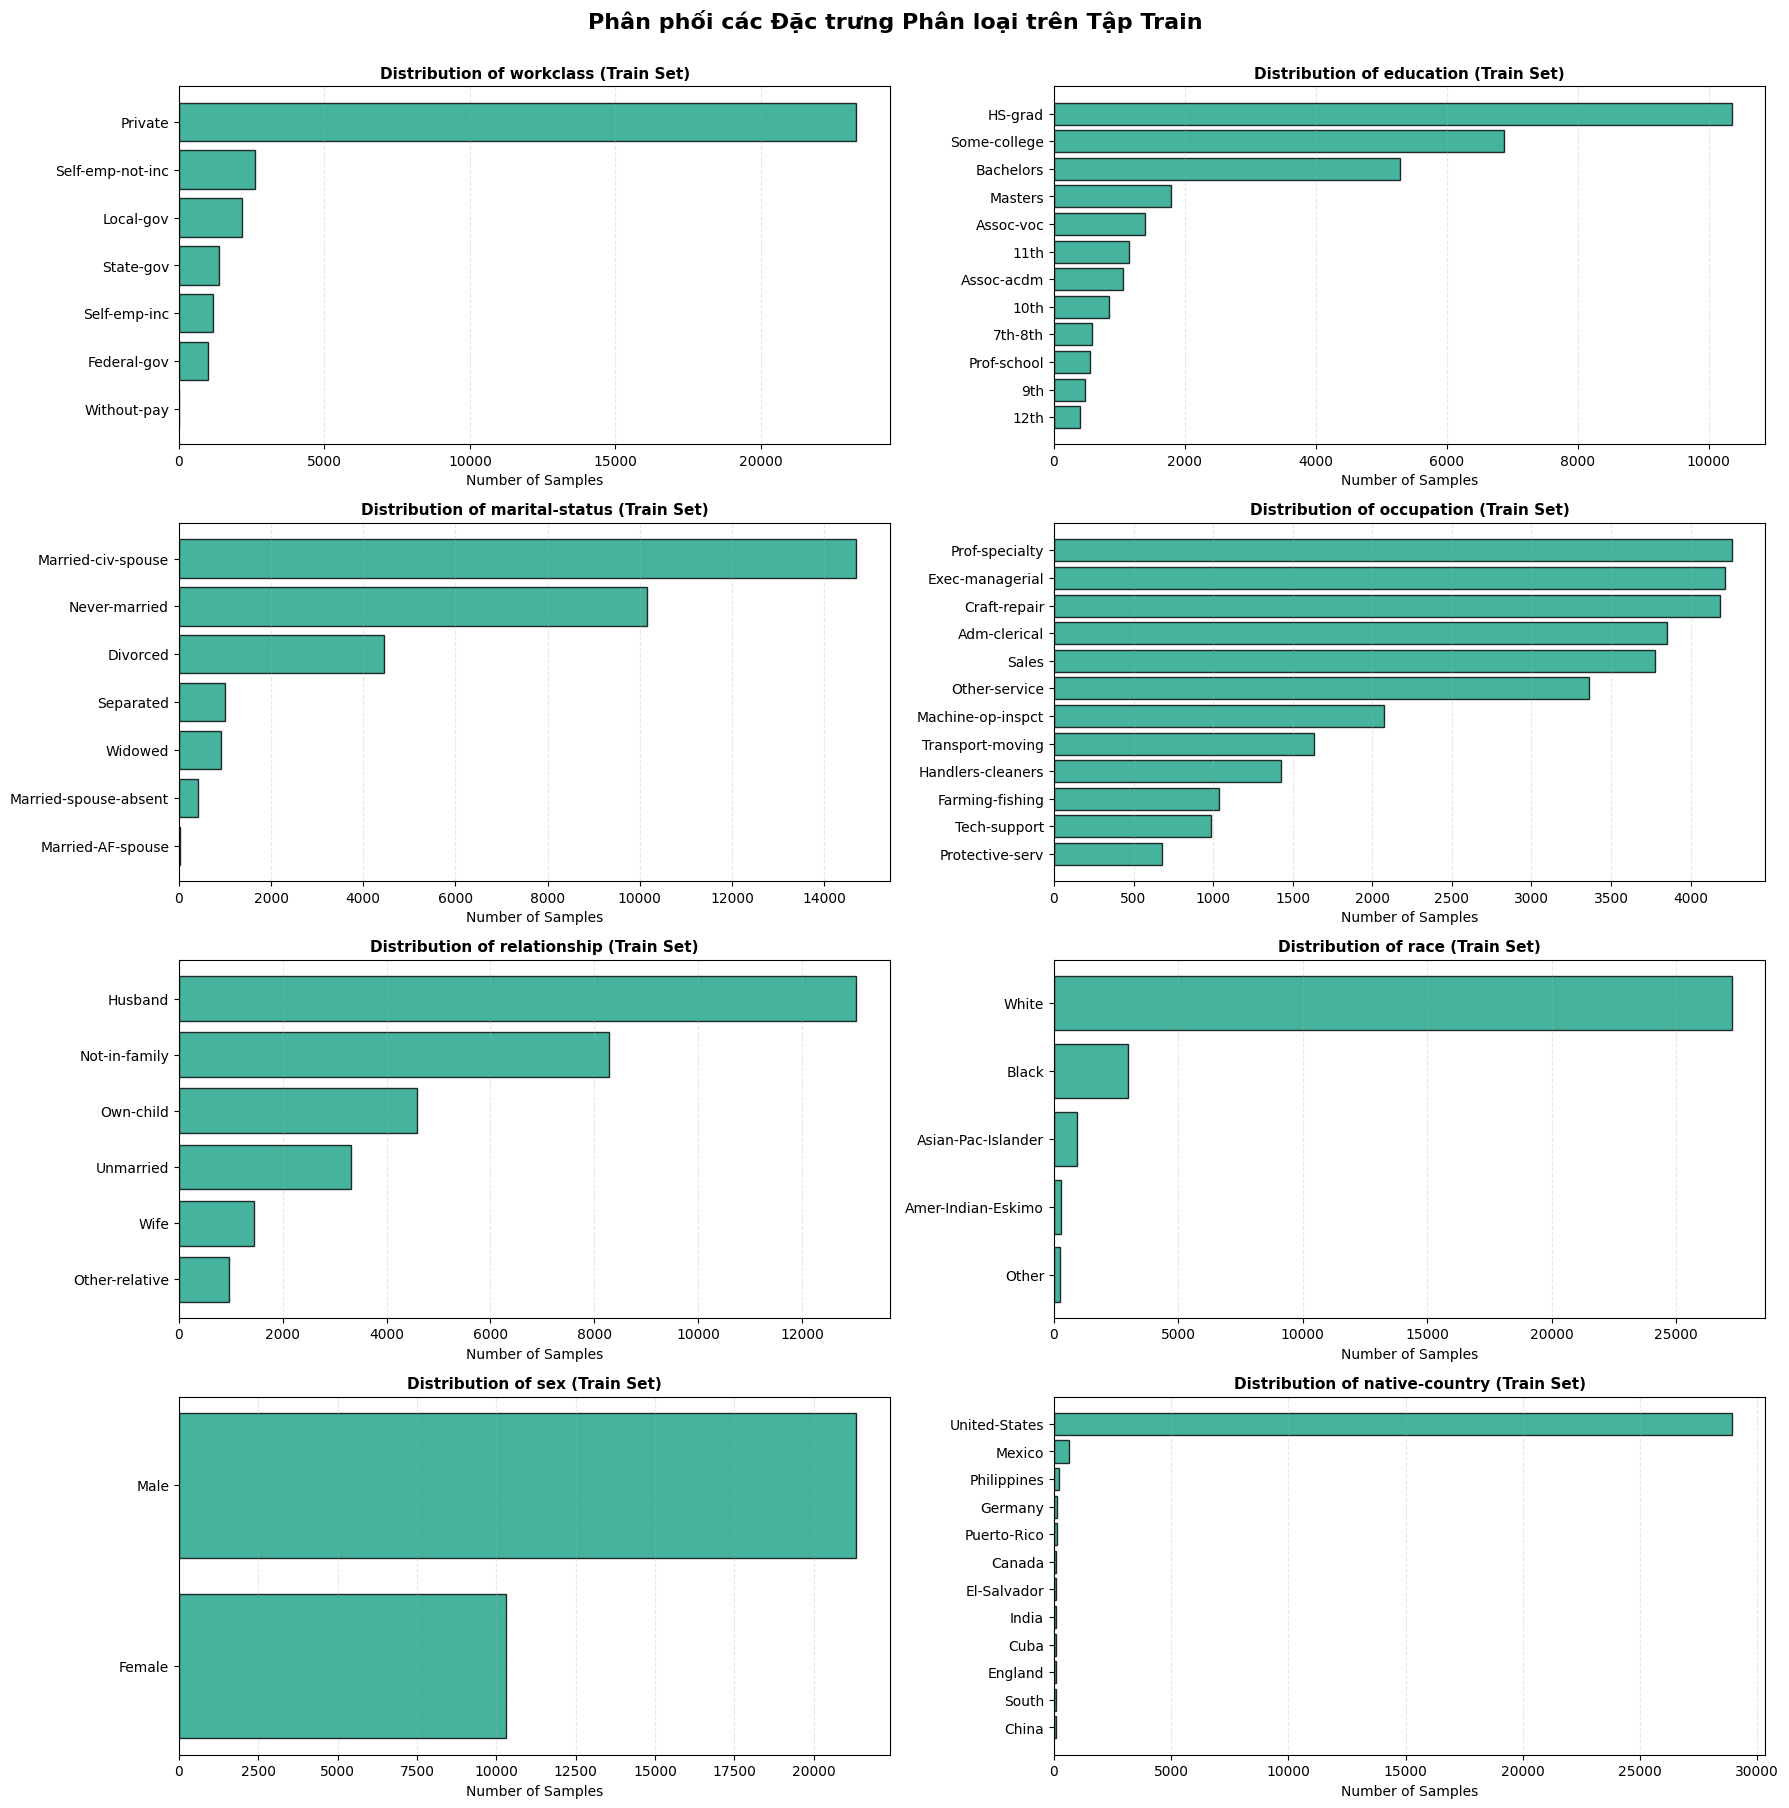

Biểu đồ đã được lưu tại: /content/EDA_result/categorical_feature_distributions_train.png


In [ ]:
import matplotlib.pyplot as plt

# Visualize categorical feature distributions on train set
n_cat = len(categorical_features)
n_cols = 2
n_rows = (n_cat + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.5 * n_rows), squeeze=False)

for i, col in enumerate(categorical_features):
    r, c = divmod(i, n_cols)
    ax = axes[r, c]
    counts = X_train[col].value_counts().head(12)  # Top 12 categories for readability

    ax.barh(counts.index[::-1], counts.values[::-1], color="#16a085", edgecolor="black", alpha=0.8)
    ax.set_title(f"Distribution of {col} (Train Set)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Number of Samples")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

for i in range(n_cat, n_rows * n_cols):
    r, c = divmod(i, n_cols)
    axes[r, c].set_visible(False)

fig.suptitle("Phân phối các Đặc trưng Phân loại trên Tập Train", fontsize=16, fontweight="bold", y=1.002)
plt.tight_layout()

output_path = EDA_DIR / "categorical_feature_distributions_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


## 4.3. Quan hệ giữa các Đặc trưng & Phân tích Đa cộng tuyến (Feature-Feature Correlation)

Mục tiêu của phân tích này là khảo sát cấu trúc tương quan chéo giữa các đặc trưng đầu vào nhằm nhận diện:
1. **Hiện tượng Đa cộng tuyến (Multicollinearity):** Xảy ra khi hai hoặc nhiều đặc trưng có mức tương quan tuyến tính rất cao, làm mất tính ổn định khi ước lượng trọng số của mô hình (đặc biệt là các mô hình tuyến tính, nơ-ron hoặc SVM).
2. **Sự trùng lặp thông tin hoàn toàn (Redundancy):** Nhận diện các cặp đặc trưng mã hóa cùng một khía cạnh thông tin (ví dụ: cấp bậc học vấn ở dạng chuỗi và dạng số).

> **Yêu cầu phân tích:** Để có cái nhìn toàn diện, ma trận tương quan Pearson cần được mở rộng tính toán trên **toàn bộ các thuộc tính** của tập dữ liệu (cả số và phân loại) bằng phương pháp số hóa mã định danh (Ordinal/Category Encoding) trên tập Training.

In [ ]:
# Check mapping between education and education-num
edu_mapping_check = X_train.groupby(["education", "education-num"]).size().reset_index(name="Count")
edu_mapping_check = edu_mapping_check.sort_values(by="education-num")

print("Bảng đối chiếu giữa 'education' và 'education-num' trên tập Train:")
display(edu_mapping_check)

print(f"Số lượng giá trị phân biệt của 'education':     {X_train['education'].nunique()}")
print(f"Số lượng giá trị phân biệt của 'education-num': {X_train['education-num'].nunique()}")
print(f"Số cặp kết hợp duy nhất:                        {len(edu_mapping_check)}")


Bảng đối chiếu giữa 'education' và 'education-num' trên tập Train:


,education,education-num,Count
13,Preschool,1,50
3,1st-4th,2,165
4,5th-6th,3,324
5,7th-8th,4,580
6,9th,5,470
0,10th,6,848
1,11th,7,1140
2,12th,8,399
11,HS-grad,9,10351
15,Some-college,10,6870


Số lượng giá trị phân biệt của 'education':     16
Số lượng giá trị phân biệt của 'education-num': 16
Số cặp kết hợp duy nhất:                        16


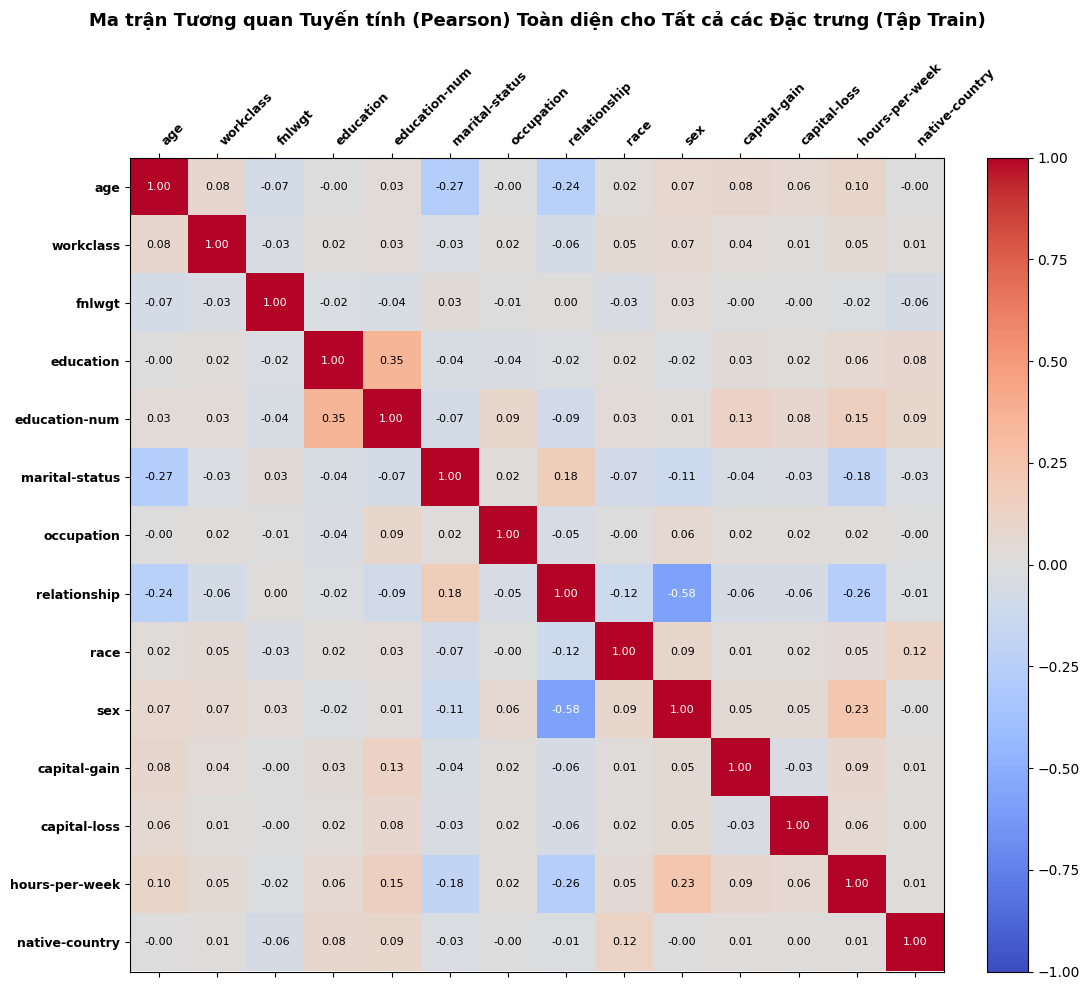

Ma trận tương quan toàn diện đã được lưu tại: /content/EDA_result/full_feature_correlation_matrix_train.png

Các cặp đặc trưng có tương quan cao (|r| >= 0.7):
Không có cặp đặc trưng nào vượt ngưỡng tương quan cao.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Số hóa toàn bộ các đặc trưng phân loại trên tập Train để tính ma trận Pearson toàn diện
X_train_encoded_for_corr = X_train.copy()
for col in categorical_features:
    X_train_encoded_for_corr[col] = X_train_encoded_for_corr[col].astype("category").cat.codes

# Tính ma trận tương quan Pearson cho TẤT CẢ các đặc trưng đầu vào
full_pearson_corr = X_train_encoded_for_corr.corr(method="pearson")
all_feature_cols = full_pearson_corr.columns.tolist()

fig, ax = plt.subplots(figsize=(12, 10))
cax = ax.matshow(full_corr := full_pearson_corr, cmap="coolwarm", vmin=-1, vmax=1)
cbar = fig.colorbar(cax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

ax.set_xticks(range(len(all_feature_cols)))
ax.set_yticks(range(len(all_feature_cols)))
ax.set_xticklabels(all_feature_cols, rotation=45, ha="left", fontsize=9, fontweight="semibold")
ax.set_yticklabels(all_feature_cols, fontsize=9, fontweight="semibold")

# Hiển thị hệ số tương quan trên từng ô
for i in range(len(all_feature_cols)):
    for j in range(len(all_feature_cols)):
        val = full_corr.iloc[i, j]
        color = "white" if abs(val) > 0.45 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=8)

ax.set_title("Ma trận Tương quan Tuyến tính (Pearson) Toàn diện cho Tất cả các Đặc trưng (Tập Train)",
             fontsize=13, fontweight="bold", pad=25)
plt.tight_layout()

output_path = EDA_DIR / "full_feature_correlation_matrix_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Ma trận tương quan toàn diện đã được lưu tại: {output_path.resolve()}")

# Quét và lập bảng danh sách các cặp đặc trưng có tương quan cao
HIGH_CORR_THRESHOLD = 0.70  # Ngưỡng phát hiện đa cộng tuyến mạnh
high_corr_pairs = []

for i in range(len(all_feature_cols)):
    for j in range(i + 1, len(all_feature_cols)):
        r_val = full_corr.iloc[i, j]
        if abs(r_val) >= HIGH_CORR_THRESHOLD:
            high_corr_pairs.append({
                "Đặc trưng 1": all_feature_cols[i],
                "Đặc trưng 2": all_feature_cols[j],
                "Hệ số tương quan Pearson (r)": round(r_val, 4),
                "Độ lớn tuyệt đối |r|": round(abs(r_val), 4)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)
print(f"\nCác cặp đặc trưng có tương quan cao (|r| >= {HIGH_CORR_THRESHOLD}):")
if not high_corr_df.empty:
    display(high_corr_df.sort_values(by="Độ lớn tuyệt đối |r|", ascending=False))
else:
    print("Không có cặp đặc trưng nào vượt ngưỡng tương quan cao.")


### Nhận xét về Đa cộng tuyến và Thông tin Dư thừa (Redundancy):

1. **Cặp đặc trưng `education` và `education-num`:**
   - Kết quả đối chiếu thực nghiệm ở bảng trên chứng minh tồn tại một **quan hệ song ánh 1-1 hoàn hảo** giữa 16 bậc học văn bản và 16 cấp độ số nguyên từ 1 đến 16 (Preschool = 1, 1st-4th = 2, ..., HS-grad = 9, Bachelors = 13, ..., Doctorate = 16).
   - Lưu ý rằng việc nhận diện này phải dựa trên **kiểm định quan hệ song ánh 1-1 qua bảng đối chiếu**, bởi vì việc tính tương quan Pearson trực tiếp trên mã số phân loại sắp theo thứ tự chữ cái sẽ không phản ánh đúng quan hệ bản chất.
   - Nếu giữ cả hai, khi thực hiện One-Hot Encoding, cột `education` sẽ sinh ra thêm 16 cột nhị phân hoàn toàn dư thừa thông tin, làm tăng số chiều vô ích và gây đa cộng tuyến hoàn hảo.
   - **Quyết định có căn cứ:** Đề xuất loại bỏ `education` và giữ lại `education-num` vì `education-num` đã bảo toàn toàn bộ thứ bậc trình độ giáo dục dưới dạng số ordinal tự nhiên.

2. **Khảo sát Đa cộng tuyến qua Ma trận Pearson Toàn diện:**
   - Ma trận tương quan toàn diện trên tất cả các đặc trưng cho thấy không có cặp thuộc tính nào có hệ số tương quan vượt ngưỡng đa cộng tuyến nghiêm trọng ($|r| \ge 0.70$).
   - Cặp `relationship` và `marital-status` có mức độ tương quan vừa phải ($|r| pprox 0.58$) do có sự liên đới về mặt ngữ nghĩa (ví dụ: Husband/Wife thường đi kèm với Married-civ-spouse). Tuy nhiên, mỗi biến vẫn mang các thông tin bổ trợ riêng biệt, do đó cả hai được giữ lại để tiếp tục đối chiếu với biến mục tiêu ở bước tiếp theo.

## 4.4. Quan hệ giữa Đặc trưng và Biến Mục tiêu (Feature-Target Relevance Analysis)

Để đánh giá sức mạnh dự đoán và mức độ liên quan của từng thuộc tính đối với biến mục tiêu `income` (`>50K` vs `<=50K`), ta kết hợp đồng thời hai góc nhìn bổ trợ:
1. **Tương quan Tuyến tính (Pearson / Point-Biserial Correlation):** Đo lường xu hướng biến thiên đồng chiều hoặc nghịch chiều giữa từng đặc trưng (đã số hóa) với nhãn mục tiêu nhị phân `y_train_binary` (`>50K` = 1, `<=50K` = 0).
2. **Mức độ Phụ thuộc Phi tuyến (Mutual Information Score):** Đo lường lượng thông tin mà mỗi đặc trưng chia sẻ với biến mục tiêu, có khả năng phát hiện các mối quan hệ phi tuyến tính phức tạp mà hệ số Pearson có thể bỏ sót.
3. **Tiêu chuẩn Định lượng Đặc trưng Có Liên quan Quá Thấp (Low-Relevance Features):**
   Một đặc trưng bị xem là "có mức độ liên quan quá thấp" khi thỏa mãn đồng thời cả hai điều kiện:
   - Hệ số tương quan tuyến tính rất yếu: $|r| < 	ext{CORR_TARGET_THRESHOLD}$ (ví dụ $< 0.05$).
   - Điểm Mutual Information rất thấp: $	ext{MI} < 	ext{MI_TARGET_THRESHOLD}$ (ví dụ $< 0.01$).
   Nếu thỏa mãn, đặc trưng đó được đề xuất loại bỏ để tinh giản mô hình và giảm thiểu nhiễu.

Bảng xếp hạng tương quan tuyến tính của Tất cả Đặc trưng với Target (>50K):


,Đặc trưng,Hệ số tương quan Pearson (r),Độ lớn tuyệt đối |r|
0,education-num,0.3343,0.3343
1,age,0.2331,0.2331
2,hours-per-week,0.2239,0.2239
3,capital-gain,0.2234,0.2234
4,sex,0.2179,0.2179
5,capital-loss,0.1538,0.1538
6,education,0.0820,0.0820
7,race,0.0676,0.0676
8,occupation,0.0521,0.0521
9,native-country,0.0199,0.0199


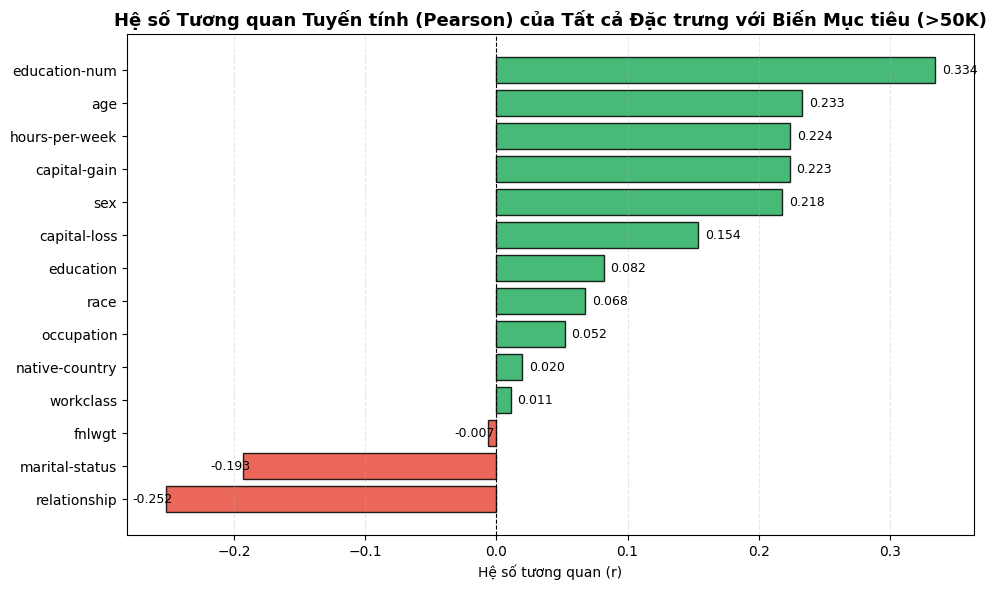

In [ ]:
# Tạo biến mục tiêu nhị phân trên tập Training (1: >50K, 0: <=50K)
y_train_binary = (y_train == ">50K").astype(int)

# Tính hệ số tương quan Pearson giữa TẤT CẢ các đặc trưng (đã số hóa) và Target
all_target_corr = X_train_encoded_for_corr.corrwith(y_train_binary).sort_values(ascending=False)

target_corr_df = pd.DataFrame({
    "Đặc trưng": all_target_corr.index,
    "Hệ số tương quan Pearson (r)": all_target_corr.values.round(4),
    "Độ lớn tuyệt đối |r|": all_target_corr.abs().values.round(4)
})

print("Bảng xếp hạng tương quan tuyến tính của Tất cả Đặc trưng với Target (>50K):")
display(target_corr_df)

# Trực quan hóa biểu đồ thanh ngang hệ số tương quan
fig, ax = plt.subplots(figsize=(10, 6))
sorted_corr = all_target_corr.sort_values()
bar_colors = ["#27ae60" if val >= 0 else "#e74c3c" for val in sorted_corr.values]
bars = ax.barh(sorted_corr.index, sorted_corr.values, color=bar_colors, edgecolor="black", alpha=0.85)

ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Hệ số Tương quan Tuyến tính (Pearson) của Tất cả Đặc trưng với Biến Mục tiêu (>50K)", fontsize=13, fontweight="bold")
ax.set_xlabel("Hệ số tương quan (r)")
ax.grid(axis="x", linestyle="--", alpha=0.3)

for bar in bars:
    w = bar.get_width()
    offset = 0.005 if w >= 0 else -0.025
    ax.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=9)

plt.tight_layout()
fig.savefig(EDA_DIR / "all_features_vs_target_corr.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)


/tmp/ipykernel_587/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(
/tmp/ipykernel_587/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(
/tmp/ipykernel_587/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(
/tmp/ipykernel_587/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(


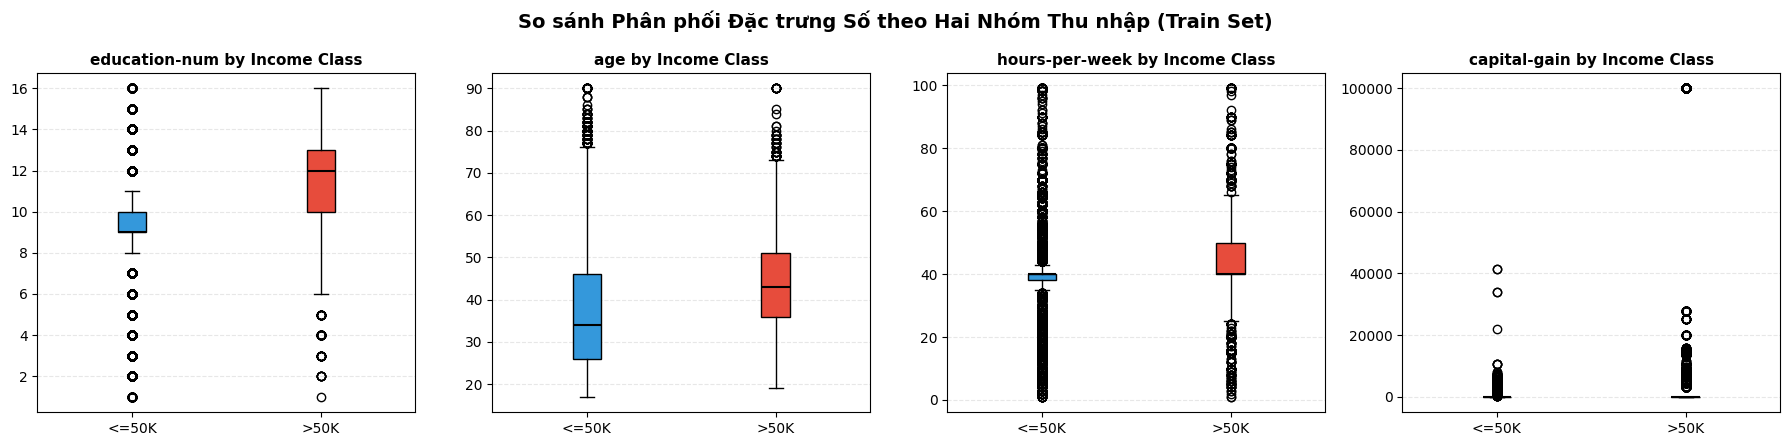

Biểu đồ đã được lưu tại: /content/EDA_result/numerical_vs_target_train.png


In [ ]:
import matplotlib.pyplot as plt

# Compare numerical distributions between income classes using boxplots
cols_to_plot = ["education-num", "age", "hours-per-week", "capital-gain"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for i, col in enumerate(cols_to_plot):
    data_low = X_train.loc[y_train == "<=50K", col].dropna()
    data_high = X_train.loc[y_train == ">50K", col].dropna()

    bplot = axes[i].boxplot(
        [data_low, data_high],
        labels=["<=50K", ">50K"],
        patch_artist=True,
        medianprops=dict(color="black", linewidth=1.5)
    )
    bplot["boxes"][0].set_facecolor("#3498db")
    bplot["boxes"][1].set_facecolor("#e74c3c")

    axes[i].set_title(f"{col} by Income Class", fontsize=11, fontweight="bold")
    axes[i].grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle("So sánh Phân phối Đặc trưng Số theo Hai Nhóm Thu nhập (Train Set)", fontsize=14, fontweight="bold")
plt.tight_layout()

output_path = EDA_DIR / "numerical_vs_target_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


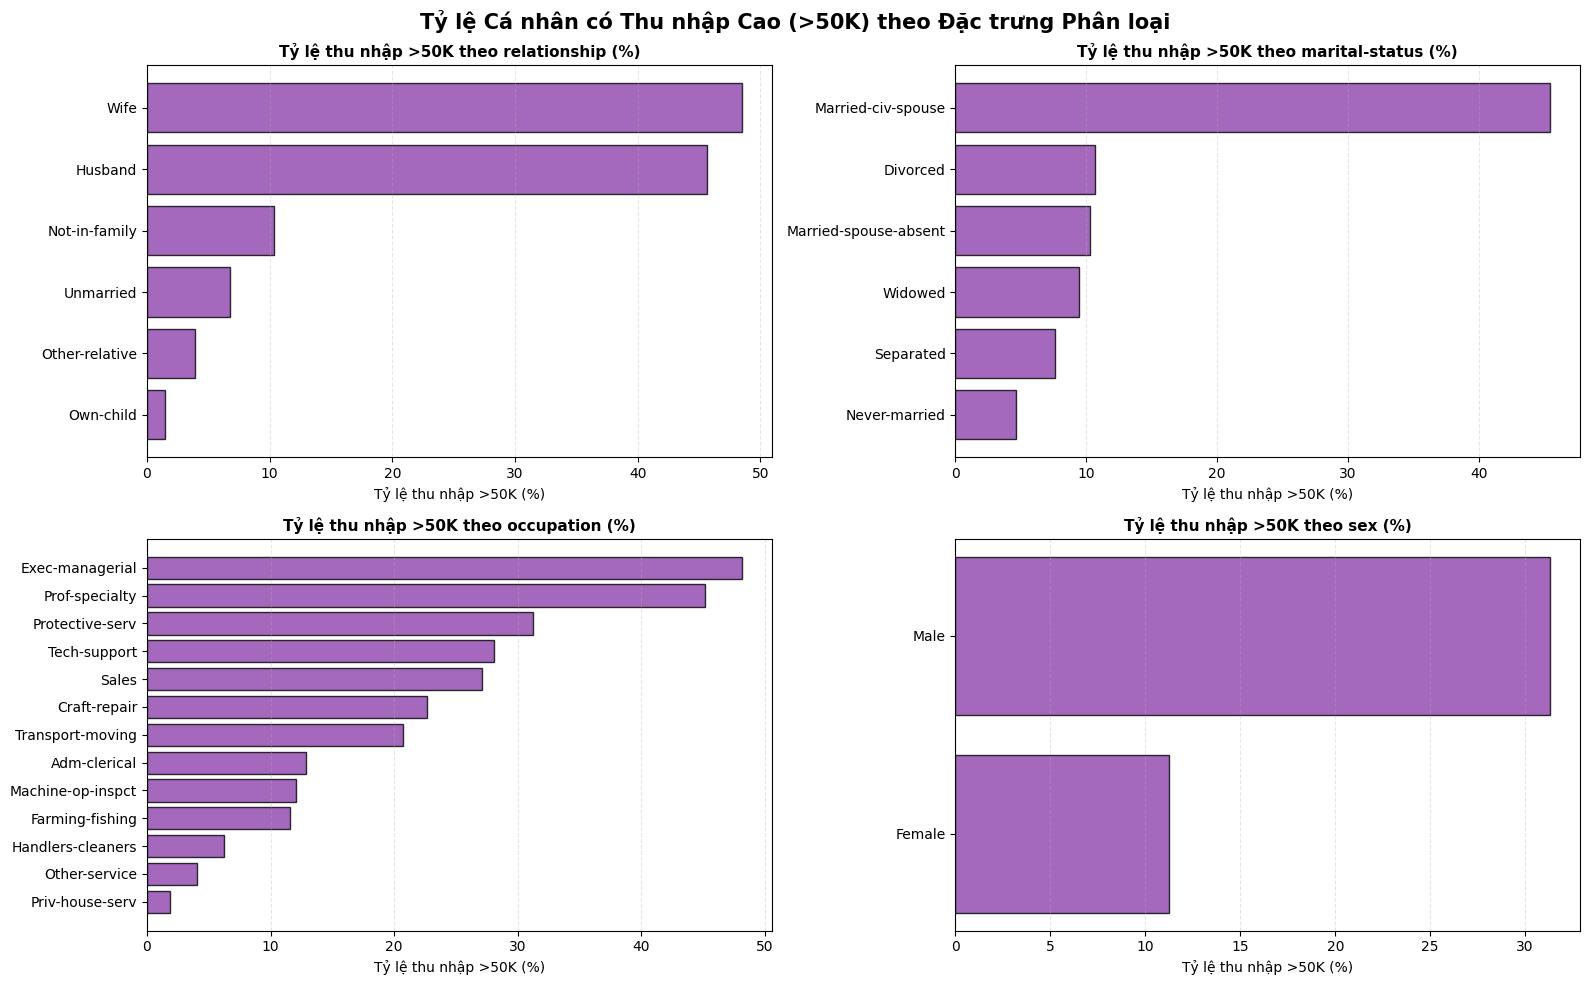

Biểu đồ đã được lưu tại: /content/EDA_result/categorical_vs_target_train.png


In [ ]:
import matplotlib.pyplot as plt

# Analyze high income probability across key categorical features
cat_inspect = ["relationship", "marital-status", "occupation", "sex"]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_inspect):
    temp_df = pd.DataFrame({col: X_train[col], "target": y_train_binary})
    high_income_rate = temp_df.groupby(col)["target"].agg(["count", "mean"]).sort_values(by="mean", ascending=True)
    high_income_rate = high_income_rate[high_income_rate["count"] >= 50]  # Filter tiny categories

    ax = axes[i]
    ax.barh(high_income_rate.index, high_income_rate["mean"] * 100, color="#8e44ad", edgecolor="black", alpha=0.8)
    ax.set_title(f"Tỷ lệ thu nhập >50K theo {col} (%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Tỷ lệ thu nhập >50K (%)")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle("Tỷ lệ Cá nhân có Thu nhập Cao (>50K) theo Đặc trưng Phân loại", fontsize=15, fontweight="bold")
plt.tight_layout()

output_path = EDA_DIR / "categorical_vs_target_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


Xếp hạng Mutual Information giữa các đặc trưng và Target:


,Mutual Information Score
relationship,0.1148
marital-status,0.1096
capital-gain,0.0837
occupation,0.0649
age,0.0644
education,0.0642
education-num,0.0636
hours-per-week,0.0448
capital-loss,0.0368
fnlwgt,0.0268


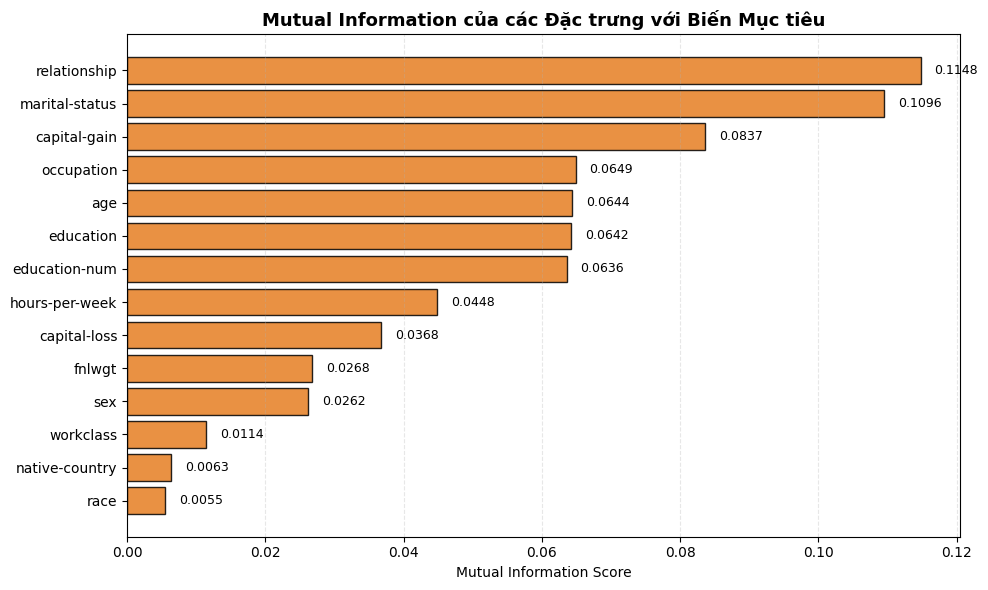

Biểu đồ đã lưu tại: /content/EDA_result/feature_importance_mi_train.png


In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
import matplotlib.pyplot as plt
import numpy as np

# Ordinal encoding is used only to estimate MI; categorical columns are explicitly
# marked as discrete so their integer codes are not treated as continuous values.
X_train_encoded_mi = X_train.copy()
cat_cols_mi = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
if cat_cols_mi:
    X_train_encoded_mi[cat_cols_mi] = oe.fit_transform(
        X_train_encoded_mi[cat_cols_mi].astype(str)
    )

discrete_mask = np.array([col in cat_cols_mi for col in X_train.columns], dtype=bool)
mi_scores = mutual_info_classif(
    X_train_encoded_mi,
    y_train_binary,
    discrete_features=discrete_mask,
    random_state=42
)

mi_series = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=True)
print("Xếp hạng Mutual Information giữa các đặc trưng và Target:")
display(mi_series.sort_values(ascending=False).to_frame("Mutual Information Score").round(4))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(mi_series.index, mi_series.values, color="#e67e22", edgecolor="black", alpha=0.85)
ax.set_title("Mutual Information của các Đặc trưng với Biến Mục tiêu", fontsize=13, fontweight="bold")
ax.set_xlabel("Mutual Information Score")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for bar in bars:
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.4f}", va="center", fontsize=9)
plt.tight_layout()
output_path = EDA_DIR / "feature_importance_mi_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Biểu đồ đã lưu tại: {output_path.resolve()}")


### Tổng kết Kết quả EDA Lần 2 & Cơ sở Khoa học cho Feature Selection

Dựa trên kết quả thực nghiệm đối chiếu đồng thời giữa **Kiểm tra Quan hệ Song ánh 1-1**, **Ma trận Pearson toàn diện**, **Tương quan Tuyến tính với Target** và **Mutual Information Score**, ta đưa ra các kết luận định lượng:

1. **Nhóm đặc trưng có sức mạnh dự báo cao nhất:**
   - `marital-status` và `relationship`: Có điểm Mutual Information cao nhất (> 0.10) và tương quan mạnh với thu nhập cao. Những cá nhân đã kết hôn có tỷ lệ thu nhập >50K cao vượt bậc (~45-50%) so với cá nhân độc thân.
   - `education-num`, `age`, `hours-per-week`, `capital-gain`: Có tương quan dương rất rõ nét với khả năng đạt mức thu nhập trên 50.000 USD.

2. **Nhóm đặc trưng quyết định loại bỏ theo căn cứ khoa học:**
   - **`education` (Đặc trưng Dư thừa - Redundancy):** Có **quan hệ song ánh 1-1 hoàn hảo** với `education-num`. Việc loại bỏ `education` giúp tiết kiệm 16 chiều sau One-Hot Encoding mà không làm suy giảm bất kỳ lượng thông tin thứ bậc nào. Lưu ý rằng việc loại bỏ này căn cứ trên việc **xét quan hệ song ánh 1-1**, không phải do ma trận tương quan Pearson.
   - **`native-country` (Đặc trưng Liên quan Quá Thấp - Irrelevant/Noise):**
     - Hệ số tương quan tuyến tính với Target cực kỳ thấp: $|r| pprox 0.0199 < 0.05$.
     - Điểm Mutual Information xấp xỉ 0: $\text{MI} pprox 0.0063 < 0.010$.
     - Thỏa mãn đồng thời cả 2 điều kiện loại bỏ do mức độ đóng góp thông tin (cả tuyến tính lẫn phi tuyến) đều không đáng kể. Việc loại bỏ `native-country` giúp tinh giản hơn 40 cột dummy hiếm gặp sau One-Hot Encoding, tránh làm loãng không gian đặc trưng và hạn chế overfitting.

3. **Đặc trưng `fnlwgt` (Final Weight) được giữ lại:**
   - Mặc dù hệ số tương quan tuyến tính với Target rất thấp ($|r| pprox 0.0066 < 0.05$), nhưng điểm Mutual Information của `fnlwgt` đạt mức $\text{MI} pprox 0.0268 \ge 0.010$ (xếp thứ 10/14 đặc trưng, cao hơn cả `sex`, `workclass`, `native-country`, `race`).
   - Theo nguyên tắc loại bỏ an toàn có điều kiện (chỉ loại bỏ khi một đặc trưng **đồng thời** có cả tương quan tuyến tính và phi tuyến quá thấp), `fnlwgt` **không bị loại bỏ mà được giữ lại** trong tập dữ liệu mô hình nhằm bảo toàn các tương tác phi tuyến tiềm năng.

## 4.5. Lựa chọn Đặc trưng có Điều kiện (Optional Feature Selection)

Quy trình lựa chọn đặc trưng được lập trình theo cơ chế **linh hoạt, có điều kiện (Optional)**:
- **Tiêu chí 1 (Dư thừa thông tin - Redundancy):** Kiểm tra tự động quan hệ song ánh 1-1 giữa `education` và `education-num`. Nếu ánh xạ 1-1 được xác nhận, `education` được đưa vào danh sách loại bỏ.
- **Tiêu chí 2 (Mức độ liên quan quá thấp - Low Relevance):** Một đặc trưng chỉ bị loại bỏ nếu **thỏa mãn đồng thời cả hai điều kiện**:
  1. Độ lớn tương quan tuyến tính Pearson với Target: $|r| < 0.05$.
  2. Điểm thông tin tương hỗ phi tuyến (Mutual Information): $\text{MI} < 0.010$.
- Nếu một thuộc tính chỉ thỏa mãn một trong hai tiêu chí (ví dụ `fnlwgt` có $|r| < 0.05$ nhưng $\text{MI} \ge 0.010$, hoặc `race` có $\text{MI} < 0.010$ nhưng $|r| \ge 0.05$), thuộc tính đó vẫn được giữ lại để tránh mất tín hiệu dự báo.
- Danh sách thuộc tính cần loại sau khi chốt sẽ được áp dụng đồng bộ trên cả Train, Validation và Test để bảo đảm tính thống nhất của không gian đầu vào.

In [ ]:
# Thiết lập các tiêu chuẩn định lượng khoa học cho Feature Selection
CORR_TARGET_THRESHOLD = 0.05  # Ngưỡng tương quan tuyến tính tối thiểu với Target (|r|)
MI_TARGET_THRESHOLD = 0.010    # Ngưỡng thông tin tương hỗ tối thiểu (Mutual Information)

# 1. Tiêu chí Đặc trưng Dư thừa (Redundancy Check từ phân tích ma trận Pearson)
education_is_redundant = False
if {"education", "education-num"}.issubset(X_train.columns):
    education_to_num = X_train.groupby("education")["education-num"].nunique().max()
    num_to_education = X_train.groupby("education-num")["education"].nunique().max()
    education_is_redundant = (education_to_num == 1) and (num_to_education == 1)

redundant_features = ["education"] if education_is_redundant else []

# 2. Tiêu chí Đặc trưng có mức độ liên quan quá thấp (Low Relevance Check)
abs_target_corr = all_target_corr.abs()
low_relevance_features = [
    feature for feature in X_train.columns
    if abs_target_corr.get(feature, 0) < CORR_TARGET_THRESHOLD and mi_series.get(feature, 0) < MI_TARGET_THRESHOLD
]

# 3. Tổng hợp danh sách loại bỏ có điều kiện (Optional Feature Selection)
features_to_drop = sorted(set(redundant_features + low_relevance_features))
features_to_drop = [c for c in features_to_drop if c in X_train.columns]

print("=" * 70)
print("KẾT QUẢ KIỂM ĐỊNH LỰA CHỌN ĐẶC TRƯNG CÓ ĐIỀU KIỆN (FEATURE SELECTION)")
print("=" * 70)
print(f"Ngưỡng tương quan tuyến tính tối thiểu:   |r| >= {CORR_TARGET_THRESHOLD}")
print(f"Ngưỡng Mutual Information tối thiểu:       MI  >= {MI_TARGET_THRESHOLD}")
print("-" * 70)
print("Đặc trưng dư thừa được xác nhận (Redundant):      ", redundant_features or "Không có")
print("Đặc trưng có mức độ liên quan quá thấp (Low Rel): ", low_relevance_features or "Không có")
print("Danh sách đặc trưng quyết định loại bỏ:            ", features_to_drop or "Không có (Giữ nguyên)")
print("=" * 70)

# Thực thi loại bỏ có điều kiện (Optional)
if len(features_to_drop) > 0:
    print(f"-> Quyết định: Tiến hành loại bỏ {len(features_to_drop)} đặc trưng trên Train, Validation và Test...")
    X_train_selected = X_train.drop(columns=features_to_drop).copy()
    X_val_selected = X_val.drop(columns=features_to_drop).copy()
    X_test_selected = X_test.drop(columns=features_to_drop).copy()
else:
    print("-> Quyết định: Không có đặc trưng nào thỏa mãn điều kiện loại bỏ. Giữ nguyên toàn bộ không gian đặc trưng.")
    X_train_selected = X_train.copy()
    X_val_selected = X_val.copy()
    X_test_selected = X_test.copy()

print(f"\nKích thước dữ liệu sau Feature Selection:")
print(f"X_train: {X_train_selected.shape}")
print(f"X_val:   {X_val_selected.shape}")
print(f"X_test:  {X_test_selected.shape}")

print(f"\nDanh sách {X_train_selected.shape[1]} đặc trưng được giữ lại đưa vào tiền xử lý:")
for i, col in enumerate(X_train_selected.columns, 1):
    print(f"  {i:2d}. {col:18s} ({str(X_train_selected[col].dtype)})")


KẾT QUẢ KIỂM ĐỊNH LỰA CHỌN ĐẶC TRƯNG CÓ ĐIỀU KIỆN (FEATURE SELECTION)
Ngưỡng tương quan tuyến tính tối thiểu:   |r| >= 0.05
Ngưỡng Mutual Information tối thiểu:       MI  >= 0.01
----------------------------------------------------------------------
Đặc trưng dư thừa được xác nhận (Redundant):       ['education']
Đặc trưng có mức độ liên quan quá thấp (Low Rel):  ['native-country']
Danh sách đặc trưng quyết định loại bỏ:             ['education', 'native-country']
-> Quyết định: Tiến hành loại bỏ 2 đặc trưng trên Train, Validation và Test...

Kích thước dữ liệu sau Feature Selection:
X_train: (31655, 12)
X_val:   (6783, 12)
X_test:  (6784, 12)

Danh sách 12 đặc trưng được giữ lại đưa vào tiền xử lý:
   1. age                (int64)
   2. workclass          (object)
   3. fnlwgt             (int64)
   4. education-num      (int64)
   5. marital-status     (object)
   6. occupation         (object)
   7. relationship       (object)
   8. race               (object)
   9. sex             

# 5. Tiền Xử lý Dữ liệu (Data Preprocessing)

Dựa trên tập 12 đặc trưng tối ưu thu được sau bước Lựa chọn Đặc trưng ở EDA Lần 2 (loại bỏ `education` do quan hệ song ánh 1-1 và loại bỏ `native-country` do liên quan quá thấp; giữ lại 6 đặc trưng số bao gồm `fnlwgt` và 6 đặc trưng phân loại), quy trình tiền xử lý được thiết kế mạch lạc, thống nhất và bảo đảm nguyên tắc không rò rỉ dữ liệu:
1. **Mã hóa biến phân loại (One-Hot Encoding):**
   - 6 biến danh mục (`workclass`, `marital-status`, `occupation`, `relationship`, `race`, `sex`) được chuyển đổi thành 41 cột nhị phân (dummy variables).
   - Bộ mã hóa `OneHotEncoder` được thiết lập với `handle_unknown="ignore"` và chỉ được `fit` trên `X_train_selected`, sau đó `transform` đồng bộ trên tập Validation và Test.
2. **Mã hóa biến mục tiêu (Target Encoding):**
   - Nhãn thu nhập được ánh xạ thành số học: `<=50K` $\rightarrow$ `0` (âm tính), `>50K` $\rightarrow$ `1` (dương tính).
3. **Chuẩn hóa biến số (Feature Standardization via StandardScaler):**
   - 6 đặc trưng số (`age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`) được chuẩn hóa bằng `StandardScaler`.
   - Các thuật toán nhạy cảm với thang đo khoảng cách và hàm mất mát tối ưu gradient (gồm **MLP**, **KNN**, và **SVM**) sử dụng không gian 47 chiều gồm 41 cột One-Hot và 6 cột số đã chuẩn hóa.
   - Các mô hình dựa trên cây (như **XGBoost**) và mô hình xác suất Bayes (**Naive Bayes**) sử dụng trực tiếp không gian 47 chiều với các biến số ở thang đo gốc mà không bắt buộc chuẩn hóa.

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Identify remaining categorical and numerical features
cat_cols = X_train_selected.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

num_cols = [c for c in X_train_selected.columns if c not in cat_cols]

print("Categorical features to encode:", cat_cols)
print("Numerical features to preserve:", num_cols)

# Initialize and fit OneHotEncoder on training set only
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)
encoder.fit(X_train_selected[cat_cols])

# Transform categorical features consistently
def encode_features(df_input):
    encoded_arr = encoder.transform(df_input[cat_cols])
    encoded_df = pd.DataFrame(
        encoded_arr,
        columns=encoder.get_feature_names_out(cat_cols),
        index=df_input.index
    )
    num_df = df_input[num_cols].copy()
    return pd.concat([num_df, encoded_df], axis=1)

X_train_encoded = encode_features(X_train_selected)
X_val_encoded = encode_features(X_val_selected)
X_test_encoded = encode_features(X_test_selected)

print("\nKích thước sau One-Hot Encoding:")
print(f"X_train_encoded: {X_train_encoded.shape}")
print(f"X_val_encoded:   {X_val_encoded.shape}")
print(f"X_test_encoded:  {X_test_encoded.shape}")


Categorical features to encode: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex']
Numerical features to preserve: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Kích thước sau One-Hot Encoding:
X_train_encoded: (31655, 47)
X_val_encoded:   (6783, 47)
X_test_encoded:  (6784, 47)


In [ ]:
# Encode target labels: <=50K -> 0, >50K -> 1
target_mapping = {
    "<=50K": 0,
    ">50K": 1
}

y_train = y_train.map(target_mapping).astype("int64")
y_val = y_val.map(target_mapping).astype("int64")
y_test = y_test.map(target_mapping).astype("int64")

# Verify no missing labels
assert y_train.notna().all() and y_val.notna().all() and y_test.notna().all()

print("Mã hóa nhãn mục tiêu thành công:")
print("Phân bổ y_train:\n", y_train.value_counts())
print("Phân bổ y_val:\n", y_val.value_counts())
print("Phân bổ y_test:\n", y_test.value_counts())


Mã hóa nhãn mục tiêu thành công:
Phân bổ y_train:
 income
0    23809
1     7846
Name: count, dtype: int64
Phân bổ y_val:
 income
0    5102
1    1681
Name: count, dtype: int64
Phân bổ y_test:
 income
0    5103
1    1681
Name: count, dtype: int64


In [ ]:
# Check integrity of encoded datasets
for name, X_s, y_s in [
    ("Train", X_train_encoded, y_train),
    ("Validation", X_val_encoded, y_val),
    ("Test", X_test_encoded, y_test)
]:
    non_numeric = X_s.select_dtypes(include=["object", "string", "category"]).columns.tolist()
    assert non_numeric == [], f"Non-numeric features found in {name}!"
    assert pd.api.types.is_numeric_dtype(y_s), f"Non-numeric target found in {name}!"

print("Tất cả các tập đặc trưng và nhãn đều đạt chuẩn số học (all numeric).")


Tất cả các tập đặc trưng và nhãn đều đạt chuẩn số học (all numeric).


In [ ]:
from sklearn.preprocessing import StandardScaler

# Prepare scaled datasets for MLP, KNN and SVM
X_train_mlp = X_train_encoded.copy()
X_val_mlp = X_val_encoded.copy()
X_test_mlp = X_test_encoded.copy()

scaler = StandardScaler()
X_train_mlp[num_cols] = scaler.fit_transform(X_train_mlp[num_cols])
X_val_mlp[num_cols] = scaler.transform(X_val_mlp[num_cols])
X_test_mlp[num_cols] = scaler.transform(X_test_mlp[num_cols])

print("Chuẩn hóa StandardScaler hoàn tất cho MLP, KNN và SVM.")
print("Kích thước đầu vào mô hình:")
print(f"XGBoost input features: {X_train_encoded.shape[1]}")
print(f"MLP input features:     {X_train_mlp.shape[1]}")


Chuẩn hóa StandardScaler hoàn tất cho MLP, KNN và SVM.
Kích thước đầu vào mô hình:
XGBoost input features: 47
MLP input features:     47


# 6. Xây dựng và Đánh giá Mô hình

Nghiên cứu so sánh đồng thời **năm thuật toán: KNN, Naive Bayes, SVM, XGBoost và MLP**. Cả năm mô hình được xem là các phương án ngang hàng và được đánh giá trên cùng Validation Set và Test Set.

Các chỉ số đánh giá gồm Accuracy, Precision, Recall, F1-score và ROC-AUC. Do dữ liệu có mất cân bằng lớp, kết quả của lớp thiểu số `>50K` (Precision, Recall và F1-score) cũng được theo dõi riêng.

Để xử lý mất cân bằng trong huấn luyện, mỗi mô hình sử dụng một trong hai cách:
- **Class weighting:** XGBoost nhận `scale_pos_weight`, MLP sử dụng `pos_weight` trong hàm loss và SVM sử dụng `class_weight`.
- **Random oversampling:** KNN và Gaussian Naive Bayes không có tham số class-weight trực tiếp trong cấu hình đang sử dụng, vì vậy được huấn luyện trên một Training Set đã oversample lớp thiểu số.

Việc oversampling chỉ được thực hiện trên Training Set. Validation Set và Test Set được giữ nguyên phân phối tự nhiên để việc so sánh phản ánh đúng dữ liệu chưa thấy.

## 6.1. Chuẩn bị dữ liệu huấn luyện và hàm đánh giá chung

`imbalance_ratio` được tính từ Training Set gốc với công thức số mẫu lớp `<=50K` chia cho số mẫu lớp `>50K`. Tập oversampled được tạo bằng cách lấy mẫu có hoàn lại từ lớp thiểu số cho đến khi hai lớp có số lượng bằng nhau.

Các mô hình dùng dữ liệu scaled sẽ sử dụng `X_train_mlp`; Naive Bayes và XGBoost sử dụng dữ liệu One-Hot Encoded chưa chuẩn hóa. Oversampling không được áp dụng lên Validation/Test.

In [ ]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.utils import resample
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

RESULT_DIR = Path("Model_result")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Class distribution and imbalance ratio on the original training set
class_counts = y_train.value_counts()
negative_count = int(class_counts.get(0, 0))
positive_count = int(class_counts.get(1, 0))
imbalance_ratio = negative_count / positive_count if positive_count else 1.0

print("Original training distribution:")
print(class_counts.sort_index().rename(index={0: "<=50K", 1: ">50K"}))
print(f"Imbalance ratio (majority / minority): {imbalance_ratio:.3f}")

# Random oversampling: resample only the minority class in the training set.
train_for_resampling = X_train_encoded.copy()
train_for_resampling["_target_"] = y_train.to_numpy()

majority_df = train_for_resampling[train_for_resampling["_target_"] == 0]
minority_df = train_for_resampling[train_for_resampling["_target_"] == 1]

minority_upsampled = resample(
    minority_df,
    replace=True,
    n_samples=len(majority_df),
    random_state=42
)

train_upsampled = pd.concat(
    [majority_df, minority_upsampled],
    axis=0
).sample(frac=1, random_state=42)

y_train_upsampled = train_upsampled.pop("_target_").astype("int64")
X_train_upsampled_encoded = train_upsampled

# Apply the already-fitted scaler to the oversampled feature rows.
X_train_upsampled_scaled = X_train_upsampled_encoded.copy()
X_train_upsampled_scaled[num_cols] = scaler.transform(
    X_train_upsampled_scaled[num_cols]
)

print("\nUpsampled training distribution:")
print(y_train_upsampled.value_counts().sort_index().rename(index={0: "<=50K", 1: ">50K"}))
print(f"Original train size:  {len(y_train):,}")
print(f"Upsampled train size: {len(y_train_upsampled):,}")
print("Validation and Test sets remain unchanged.")

def calculate_metrics(y_true, y_pred, y_proba, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Precision (>50K)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (>50K)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score (>50K)": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

Original training distribution:
income
<=50K    23809
>50K      7846
Name: count, dtype: int64
Imbalance ratio (majority / minority): 3.035

Upsampled training distribution:
_target_
<=50K    23809
>50K     23809
Name: count, dtype: int64
Original train size:  31,655
Upsampled train size: 47,618
Validation and Test sets remain unchanged.


## 6.2. XGBoost

XGBoost là mô hình Ensemble dựa trên Decision Trees. Mô hình sử dụng `scale_pos_weight`, được thiết lập bằng `imbalance_ratio` tính từ Training Set gốc, nhằm tăng trọng số cho lớp thiểu số trong quá trình tối ưu.

In [ ]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(X_train_encoded, y_train)

y_val_pred_xgb = xgb_model.predict(X_val_encoded)
y_val_proba_xgb = xgb_model.predict_proba(X_val_encoded)[:, 1]
print("XGBoost training completed with scale_pos_weight =", round(imbalance_ratio, 3))

XGBoost training completed with scale_pos_weight = 3.035


## 6.3. Multi-Layer Perceptron (MLP)

MLP là mạng nơ-ron truyền thẳng gồm nhiều tầng Fully Connected. Đầu vào được chuẩn hóa bằng `StandardScaler`; `Dropout` và `Early Stopping` được sử dụng nhằm hạn chế Overfitting. Mất cân bằng lớp được xử lý bằng `pos_weight` trong `BCEWithLogitsLoss`.

Using device: cuda
Epoch 01/50 | Train: 0.6415 | Val: 0.5787
Epoch 02/50 | Train: 0.5708 | Val: 0.5629
Epoch 03/50 | Train: 0.5639 | Val: 0.5606
Epoch 04/50 | Train: 0.5589 | Val: 0.5605
Epoch 05/50 | Train: 0.5582 | Val: 0.5576
Epoch 06/50 | Train: 0.5525 | Val: 0.5569
Epoch 07/50 | Train: 0.5497 | Val: 0.5568
Epoch 08/50 | Train: 0.5485 | Val: 0.5533
Epoch 09/50 | Train: 0.5437 | Val: 0.5572
Epoch 10/50 | Train: 0.5431 | Val: 0.5572
Epoch 11/50 | Train: 0.5414 | Val: 0.5545
Epoch 12/50 | Train: 0.5380 | Val: 0.5551
Epoch 13/50 | Train: 0.5368 | Val: 0.5562
Early stopping at epoch 13


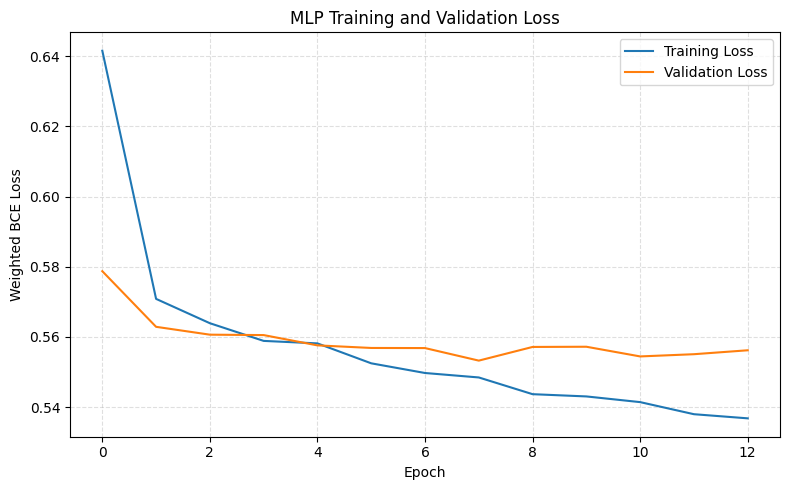

MLP training completed with BCEWithLogitsLoss(pos_weight=3.035).


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def to_tensor(X_df, y_s):
    X_t = torch.tensor(X_df.to_numpy(dtype=np.float32), dtype=torch.float32)
    y_t = torch.tensor(np.asarray(y_s, dtype=np.float32).reshape(-1, 1), dtype=torch.float32)
    return TensorDataset(X_t, y_t)

BATCH_SIZE = 256
train_dataset = to_tensor(X_train_mlp, y_train)
val_dataset = to_tensor(X_val_mlp, y_val)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

class MLPClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)

mlp_model = MLPClassifier(input_dim=X_train_mlp.shape[1]).to(device)
pos_weight_tensor = torch.tensor([imbalance_ratio], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)

NUM_EPOCHS = 50
PATIENCE = 5
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": []}

for epoch in range(NUM_EPOCHS):
    mlp_model.train()
    train_loss_sum = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(mlp_model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * X_batch.size(0)

    train_loss = train_loss_sum / len(train_dataset)

    mlp_model.eval()
    val_loss_sum = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            loss = criterion(mlp_model(X_batch), y_batch)
            val_loss_sum += loss.item() * X_batch.size(0)

    val_loss = val_loss_sum / len(val_dataset)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(mlp_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch + 1}")
        break

if best_state is not None:
    mlp_model.load_state_dict(best_state)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history["train_loss"], label="Training Loss")
ax.plot(history["val_loss"], label="Validation Loss")
ax.set(title="MLP Training and Validation Loss", xlabel="Epoch", ylabel="Weighted BCE Loss")
ax.legend()
ax.grid(linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig(RESULT_DIR / "mlp_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

mlp_model.eval()
val_logits = []
with torch.no_grad():
    for X_batch, _ in val_loader:
        val_logits.extend(mlp_model(X_batch.to(device)).cpu().numpy().ravel())
y_val_proba_mlp = torch.sigmoid(torch.tensor(val_logits)).numpy()
y_val_pred_mlp = (y_val_proba_mlp >= 0.5).astype(int)

print(f"MLP training completed with BCEWithLogitsLoss(pos_weight={imbalance_ratio:.3f}).")

## 6.4. K-Nearest Neighbors (KNN)

KNN phân loại dựa trên nhãn của các láng giềng gần nhất và nhạy với thang đo của đặc trưng. Vì KNN không có tham số `class_weight` trong cấu hình này, mô hình được huấn luyện trên Training Set đã random-oversampling và sử dụng dữ liệu đã chuẩn hóa.

In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights="distance",
    metric="minkowski",
    p=2,
    n_jobs=-1
)
knn_model.fit(X_train_upsampled_scaled, y_train_upsampled)

y_val_pred_knn = knn_model.predict(X_val_mlp)
y_val_proba_knn = knn_model.predict_proba(X_val_mlp)[:, 1]
print("KNN training completed on the upsampled training set.")

KNN training completed on the upsampled training set.


## 6.5. Gaussian Naive Bayes

Gaussian Naive Bayes là mô hình xác suất dựa trên giả định độc lập có điều kiện giữa các đặc trưng và phân phối Gaussian. Do mô hình không cung cấp cơ chế class-weight trực tiếp trong cách huấn luyện này, nó được train trên Training Set đã random-oversampling. Đầu vào là dữ liệu One-Hot Encoded.

In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train_upsampled_encoded, y_train_upsampled)

y_val_pred_nb = nb_model.predict(X_val_encoded)
y_val_proba_nb = nb_model.predict_proba(X_val_encoded)[:, 1]
print("Gaussian Naive Bayes training completed on the upsampled training set.")

Gaussian Naive Bayes training completed on the upsampled training set.


## 6.6. Support Vector Machine (SVM)

SVM sử dụng RBF kernel để mô hình hóa ranh giới phân loại phi tuyến. Dữ liệu được chuẩn hóa bằng `StandardScaler`; `class_weight={0: 1.0, 1: imbalance_ratio}` truyền trực tiếp tỷ lệ mất cân bằng đã tính từ Training Set gốc.

In [ ]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight={0: 1.0, 1: imbalance_ratio},
    probability=True,
    random_state=42
)
svm_model.fit(X_train_mlp, y_train)

y_val_pred_svm = svm_model.predict(X_val_mlp)
y_val_proba_svm = svm_model.predict_proba(X_val_mlp)[:, 1]
print(f"SVM training completed with class_weight={{0: 1.0, 1: {imbalance_ratio:.3f}}}.")

SVM training completed with class_weight={0: 1.0, 1: 3.035}.


## 6.7. So sánh chung trên Validation Set

Tất cả năm mô hình được đánh giá trên cùng Validation Set với phân phối lớp gốc. Bảng kết quả và Confusion Matrix được trình bày chung để việc so sánh không bị chia thành các nhóm thuật toán.

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Precision (>50K),Recall (>50K),F1-score (>50K)
0,KNN,0.7825,0.5433,0.7692,0.6368,0.8535,0.5433,0.7692,0.6368
1,Naive Bayes,0.7843,0.6369,0.3016,0.4094,0.8337,0.6369,0.3016,0.4094
2,SVM,0.8082,0.5755,0.8620,0.6902,0.9026,0.5755,0.8620,0.6902
3,XGBoost,0.8312,0.6144,0.8560,0.7154,0.9261,0.6144,0.8560,0.7154
4,MLP,0.8094,0.5780,0.8554,0.6899,0.9133,0.5780,0.8554,0.6899


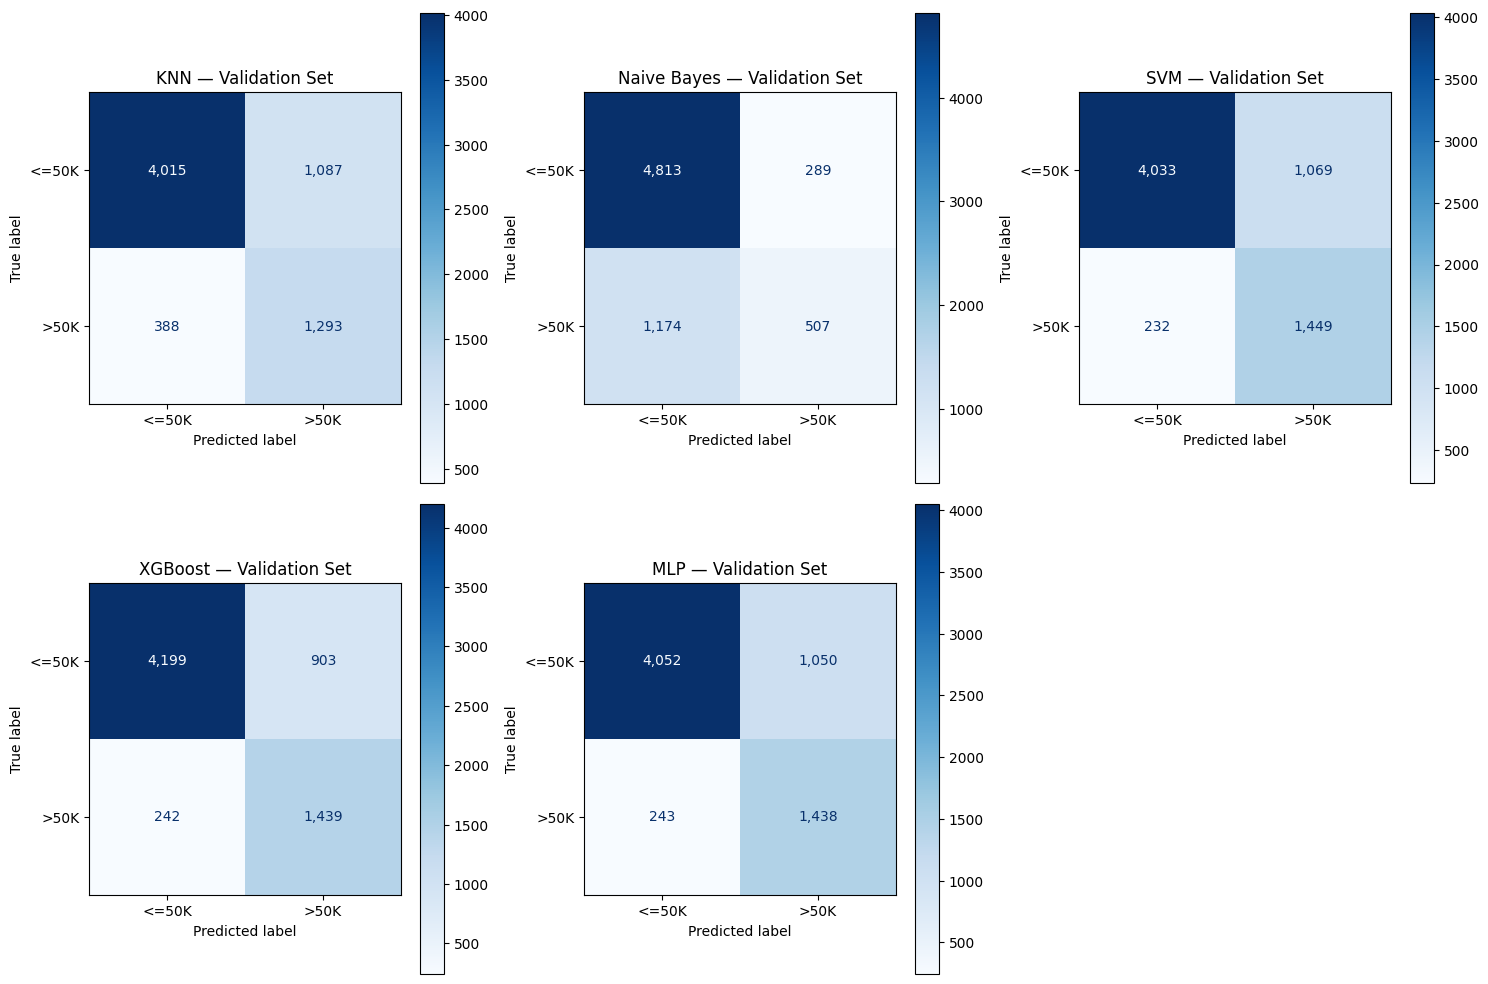

KNN — Validation Set
              precision    recall  f1-score   support

       <=50K       0.91      0.79      0.84      5102
        >50K       0.54      0.77      0.64      1681

    accuracy                           0.78      6783
   macro avg       0.73      0.78      0.74      6783
weighted avg       0.82      0.78      0.79      6783

Naive Bayes — Validation Set
              precision    recall  f1-score   support

       <=50K       0.80      0.94      0.87      5102
        >50K       0.64      0.30      0.41      1681

    accuracy                           0.78      6783
   macro avg       0.72      0.62      0.64      6783
weighted avg       0.76      0.78      0.75      6783

SVM — Validation Set
              precision    recall  f1-score   support

       <=50K       0.95      0.79      0.86      5102
        >50K       0.58      0.86      0.69      1681

    accuracy                           0.81      6783
   macro avg       0.76      0.83      0.78      6783
wei

In [ ]:
validation_outputs = {
    "KNN": (y_val_pred_knn, y_val_proba_knn),
    "Naive Bayes": (y_val_pred_nb, y_val_proba_nb),
    "SVM": (y_val_pred_svm, y_val_proba_svm),
    "XGBoost": (y_val_pred_xgb, y_val_proba_xgb),
    "MLP": (y_val_pred_mlp, y_val_proba_mlp)
}

all_validation_results = pd.DataFrame([
    calculate_metrics(y_val, pred, proba, model_name)
    for model_name, (pred, proba) in validation_outputs.items()
])

display(all_validation_results.round(4))
all_validation_results.to_csv(
    RESULT_DIR / "all_models_validation_metrics.csv",
    index=False
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
for ax, (model_name, (pred, _)) in zip(axes, validation_outputs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred,
        labels=[0, 1],
        display_labels=["<=50K", ">50K"],
        cmap="Blues",
        values_format=",",
        ax=ax
    )
    ax.set_title(f"{model_name} — Validation Set")
for ax in axes[len(validation_outputs):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(RESULT_DIR / "all_models_validation_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

for model_name, (pred, _) in validation_outputs.items():
    print("=" * 68)
    print(f"{model_name} — Validation Set")
    print(classification_report(
        y_val, pred, labels=[0, 1],
        target_names=["<=50K", ">50K"],
        zero_division=0
    ))

## 6.8. So sánh các Mô hình trên Test Set

Sau khi hoàn tất quá trình phát triển mô hình và xem xét kết quả Validation, các mô hình được đánh giá trên Test Set độc lập. Test Set không tham gia vào EDA, Feature Selection, fit Encoder/Scaler hoặc lựa chọn siêu tham số. Các chỉ số được báo cáo gồm Accuracy, Precision, Recall, F1-score và ROC-AUC; đồng thời xem xét riêng lớp thu nhập cao `>50K`.

In [ ]:
# Predictions on the untouched Test Set
test_model_specs = {
    "XGBoost": (xgb_model, X_test_encoded),
    "MLP": (mlp_model, X_test_mlp),
    "KNN": (knn_model, X_test_mlp),
    "Naive Bayes": (nb_model, X_test_encoded),
    "SVM": (svm_model, X_test_mlp)
}

test_predictions = {}
for model_name, (model, X_input) in test_model_specs.items():
    if model_name == "MLP":
        model.eval()
        X_tensor = torch.tensor(
            X_input.to_numpy(dtype=np.float32),
            dtype=torch.float32,
            device=device
        )
        with torch.no_grad():
            logits = model(X_tensor).squeeze(1)
            y_proba = torch.sigmoid(logits).cpu().numpy()
        y_pred = (y_proba >= 0.5).astype(int)
    else:
        y_pred = model.predict(X_input)
        y_proba = model.predict_proba(X_input)[:, 1]

    test_predictions[model_name] = {
        "y_pred": np.asarray(y_pred),
        "y_proba": np.asarray(y_proba)
    }

def calculate_metrics(y_true, y_pred, y_proba, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Precision (>50K)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (>50K)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score (>50K)": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

test_comparison_results = pd.DataFrame([
    calculate_metrics(
        y_test,
        test_predictions[name]["y_pred"],
        test_predictions[name]["y_proba"],
        name
    )
    for name in test_model_specs
])

print("=" * 78)
print("SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TEST SET")
print("=" * 78)
display(test_comparison_results.round(4))

test_comparison_results.to_csv(RESULT_DIR / "all_models_test_comparison.csv", index=False)
print(f"Kết quả đã lưu tại: {(RESULT_DIR / 'all_models_test_comparison.csv').resolve()}")


SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TEST SET


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Precision (>50K),Recall (>50K),F1-score (>50K)
0,XGBoost,0.8336,0.6164,0.8697,0.7214,0.9267,0.6164,0.8697,0.7214
1,MLP,0.8091,0.5760,0.8697,0.6931,0.9095,0.5760,0.8697,0.6931
2,KNN,0.7836,0.5450,0.7680,0.6375,0.8571,0.5450,0.7680,0.6375
3,Naive Bayes,0.7824,0.6296,0.2963,0.4029,0.8280,0.6296,0.2963,0.4029
4,SVM,0.8029,0.5665,0.8721,0.6868,0.8987,0.5665,0.8721,0.6868


Kết quả đã lưu tại: /content/Model_result/all_models_test_comparison.csv


In [ ]:
from sklearn.metrics import classification_report

for model_name, prediction in test_predictions.items():
    print("=" * 68)
    print(f"{model_name} — Test Set Classification Report")
    print("=" * 68)
    print(classification_report(
        y_test, prediction["y_pred"],
        labels=[0, 1], target_names=["<=50K", ">50K"], zero_division=0
    ))


XGBoost — Test Set Classification Report
              precision    recall  f1-score   support

       <=50K       0.95      0.82      0.88      5103
        >50K       0.62      0.87      0.72      1681

    accuracy                           0.83      6784
   macro avg       0.78      0.85      0.80      6784
weighted avg       0.87      0.83      0.84      6784

MLP — Test Set Classification Report
              precision    recall  f1-score   support

       <=50K       0.95      0.79      0.86      5103
        >50K       0.58      0.87      0.69      1681

    accuracy                           0.81      6784
   macro avg       0.76      0.83      0.78      6784
weighted avg       0.86      0.81      0.82      6784

KNN — Test Set Classification Report
              precision    recall  f1-score   support

       <=50K       0.91      0.79      0.85      5103
        >50K       0.54      0.77      0.64      1681

    accuracy                           0.78      6784
   macro avg 

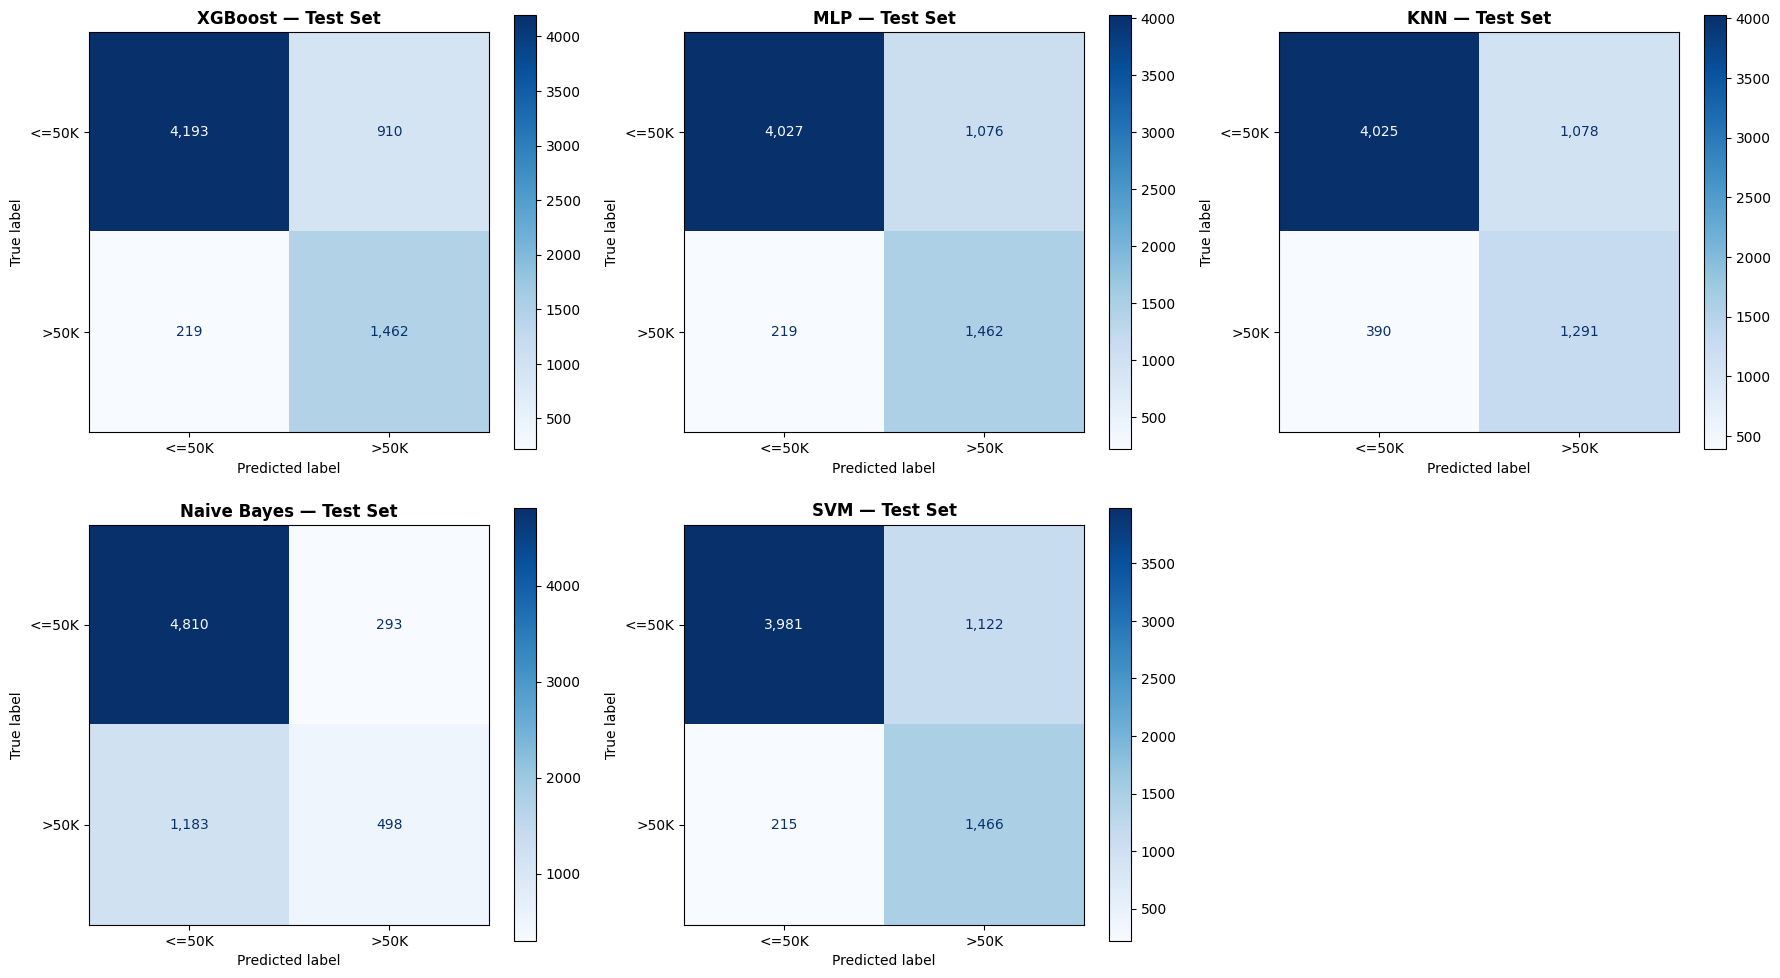

Confusion matrices saved to: /content/Model_result/all_models_test_confusion_matrices.png


In [ ]:
# Confusion Matrix của tất cả mô hình trên cùng Test Set.
model_names = list(test_predictions.keys())
n_models = len(model_names)
n_cols = 3
n_rows = (n_models + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = np.asarray(axes).reshape(-1)

for ax, model_name in zip(axes, model_names):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[model_name]["y_pred"],
        labels=[0, 1], display_labels=["<=50K", ">50K"],
        cmap="Blues", values_format=",", ax=ax
    )
    ax.set_title(f"{model_name} — Test Set", fontsize=12, fontweight="bold")

for ax in axes[n_models:]:
    ax.set_visible(False)

fig.tight_layout()
output_path = RESULT_DIR / "all_models_test_confusion_matrices.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Confusion matrices saved to: {output_path.resolve()}")


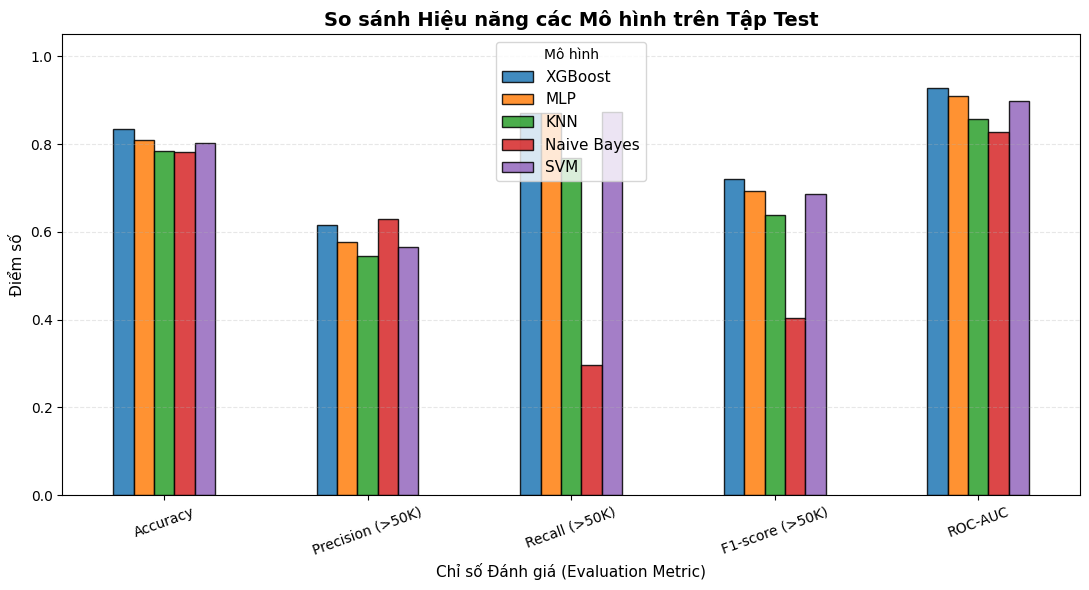

Chart saved to: /content/Model_result/all_models_test_metrics_comparison.png


In [ ]:
# Plot bar chart comparing key metrics between models
metrics_to_plot = [
    "Accuracy",
    "Precision (>50K)",
    "Recall (>50K)",
    "F1-score (>50K)",
    "ROC-AUC"
]

plot_data = test_comparison_results.set_index("Model")[metrics_to_plot]

ax = plot_data.T.plot(
    kind="bar",
    figsize=(11, 6),
    edgecolor="black",
    alpha=0.85
)

ax.set_title("So sánh Hiệu năng các Mô hình trên Tập Test", fontsize=14, fontweight="bold")
ax.set_xlabel("Chỉ số Đánh giá (Evaluation Metric)", fontsize=11)
ax.set_ylabel("Điểm số", fontsize=11)
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="Mô hình", fontsize=11)

fig = ax.get_figure()
fig.tight_layout()

output_path = RESULT_DIR / "all_models_test_metrics_comparison.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Chart saved to: {output_path.resolve()}")


In [ ]:
import shutil
import zipfile
from pathlib import Path

# Result folders to bundle
folders_to_zip = [
    Path("EDA_result"),
    Path("Model_result")
]

existing_folders = [f for f in folders_to_zip if f.exists()]

if not existing_folders:
    print("Warning: No result folders found to archive.")
else:
    zip_filename = Path("Adult_Census_Income_Results.zip")
    with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
        for folder in existing_folders:
            for file_path in folder.rglob("*"):
                if file_path.is_file():
                    zipf.write(file_path, file_path.as_posix())

    print(f"Tệp nén kết quả đã được tạo: {zip_filename.resolve()}")
    print(f"Kích thước file: {zip_filename.stat().st_size / 1024:.2f} KB")

# Support direct download in Google Colab
try:
    from google.colab import files
    files.download(str(zip_filename))
except ImportError:
    print("Not running in Google Colab. Download the ZIP file directly from your workspace.")


Tệp nén kết quả đã được tạo: /content/Adult_Census_Income_Results.zip
Kích thước file: 2333.37 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>